# Belle II Continuum Suppression

Binary signal-versus-continuum classification using the instructor's Belle II CSV. The private data is not committed.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import importlib.util
import sys
import pandas as pd
from IPython.display import Image

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.baselines import evaluate_baselines
from src.config import (
    DB_PATH, RANDOM_STATE, RAW_DATA_DIR, TEST_SIZE, VALIDATION_SIZE
)
from src.data_io import (
    assign_split, audit_frame, load_raw_to_db, prepare_professor_binary
)
from src.db import read_table, table_exists, update_cell, write_table
from src.eda import (class_balance, feature_columns, feature_correlations,
                     feature_separation, plot_class_balance,
                     plot_correlation_heatmap, plot_feature_distributions,
                     training_events)
from src.cnn import fit_cnn_validation
from src.features import analyze_feature_reduction, plot_pca_variance
from src.models import (fit_ankit_validation, fit_koustav_mlp_validation,
                        fit_vishruti_validation)

print("Project root resolved from the notebook location.")
print(
    f"Random state: {RANDOM_STATE}; split fractions: "
    f"train={1 - VALIDATION_SIZE - TEST_SIZE:.0%}, "
    f"validation={VALIDATION_SIZE:.0%}, test={TEST_SIZE:.0%}"
)

Project root resolved from the notebook location.
Random state: 42; split fractions: train=70%, validation=15%, test=15%


## 2. Instructor dataset

Use `data_hep - data_hep.csv` only. Its process flags are converted to the binary target below.

The original CSV remains private and unchanged.

## 3. Locate the instructor CSV

In [2]:
raw_csv_path = RAW_DATA_DIR / "data_hep - data_hep.csv"
if not raw_csv_path.is_file():
    raw_csv_path = None

if raw_csv_path is None:
    print("Waiting for data/raw/data_hep - data_hep.csv.")
else:
    print(f"Dataset found: {raw_csv_path.name}")

Dataset found: data_hep - data_hep.csv


## 4. Store the untouched CSV in SQLite

In [3]:
raw_events = None
if raw_csv_path is not None:
    if table_exists("raw_events", DB_PATH):
        raw_events = read_table("raw_events", DB_PATH)
        print("Read the existing immutable raw_events table.")
    else:
        raw_events = load_raw_to_db(raw_csv_path, DB_PATH)
        print("Wrote the immutable raw_events table.")
    print(f"Loaded {len(raw_events):,} rows and {raw_events.shape[1]} columns.")
else:
    print("Ingestion skipped until exactly one source CSV is available.")

Read the existing immutable raw_events table.
Loaded 70,606 rows and 61 columns.


## 5. Audit the raw data

In [4]:
raw_audit = audit_frame(raw_events) if raw_events is not None else None
if raw_audit is not None:
    print(f"Rows: {raw_audit['rows']:,}; columns: {raw_audit['columns']}")
    print(f"Duplicate rows: {raw_audit['duplicate_rows']:,}")
    print(f"Constant columns: {raw_audit['constant_columns']}")
    print(f"Six-way type counts: {raw_events['type'].value_counts().sort_index().to_dict()}")
    print(f"Missing cells: {sum(raw_audit['missing_counts'].values()):,}")
    print(f"Non-finite cells: {sum(raw_audit['non_finite_counts'].values()):,}")
    display(raw_events.head())
else:
    print("Audit skipped because no dataset has been loaded.")

Rows: 70,606; columns: 61
Duplicate rows: 0
Constant columns: []
Six-way type counts: {0: 462, 1: 35303, 2: 23333, 3: 8172, 4: 1879, 5: 1457}
Missing cells: 0
Non-finite cells: 0


,Unnamed: 0,R2,thrustBm,thrustOm,cosTBTO,cosTBz,KSFWVariables__boet__bc,KSFWVariables__bomm2__bc,CleoConeCS__bo1__bc,CleoConeCS__bo2__bc,...,KSFWVariables__bohoo2__cmFS1__bc,KSFWVariables__bohoo3__cmFS1__bc,KSFWVariables__bohoo4__cmFS1__bc,foxWolframR1,foxWolframR2,foxWolframR3,foxWolframR4,thrust,thrustAxisCosTheta,type
0,0,0.152200,0.818042,0.678908,0.925376,0.641596,5.492738,7.326161,0.062815,0.923991,...,-0.000648,-0.000956,0.003297,0.315513,0.257067,0.165595,0.099685,0.766103,0.584374,1
1,1,0.122531,0.847877,0.661546,0.203175,0.960107,3.548602,5.346302,0.000000,2.317477,...,-0.004079,0.000975,-0.010682,0.699070,0.425364,0.337010,0.357491,0.842736,0.960207,1
2,2,0.071109,0.823682,0.659284,0.586194,0.667930,7.739933,-1.734496,0.393218,0.061572,...,-0.002341,-0.002249,-0.000644,0.351783,0.278459,0.247533,0.171277,0.773620,0.723453,1
3,3,0.123307,0.849041,0.713995,0.343100,0.599684,6.336428,5.429208,0.000000,0.000000,...,-0.001151,-0.000096,0.003249,0.616451,0.581567,0.504908,0.313320,0.906921,0.631777,1
4,4,0.128661,0.850345,0.700636,0.598284,0.751411,7.520575,-1.092915,0.105494,0.789670,...,0.004459,-0.001671,-0.000072,0.099653,0.368981,0.190910,0.247606,0.824495,0.589225,1


## 6. Prepare the binary label

`prepare_professor_binary` applies the instructor's process mapping: 0 = charged B pair, 1 = neutral B pair, 2 = $c\bar c$, 3 = $u\bar u$, 4 = $d\bar d$, 5 = $s\bar s$. It combines 0/1 as signal (`target=1`) and 2/3/4/5 as continuum background (`target=0`). The original `type` and exported row number are not model inputs.

In [5]:
prepared_events = prepare_professor_binary(raw_events) if raw_events is not None else None
if prepared_events is not None:
    print(f"Rows retained: {len(prepared_events):,}/{len(raw_events):,}")
    print("Excluded from prepared data: Unnamed: 0 and six-way type")
    display(prepared_events['target'].value_counts().sort_index().rename('rows'))
else:
    print("Binary preparation waits for the professor CSV.")

Rows retained: 70,606/70,606
Excluded from prepared data: Unnamed: 0 and six-way type


target
0    34841
1    35765
Name: rows, dtype: int64

## 7. Store the 70/15/15 train/validation/test split

Split by row position, so duplicate pandas index labels cannot overlap assignments.

In [6]:
events_with_split = None
if prepared_events is not None:
    if table_exists("cleaned_events", DB_PATH):
        events_with_split = read_table("cleaned_events", DB_PATH)
        print("Read persisted cleaned_events; did not re-split.")
    else:
        events_with_split = assign_split(
            prepared_events, "target",
            validation_size=VALIDATION_SIZE, test_size=TEST_SIZE,
        )
        write_table(events_with_split, "cleaned_events", db_path=DB_PATH)
        print("Wrote cleaned_events with one persisted split.")
    display(events_with_split.groupby(["split", "target"]).size().rename("rows"))
else:
    print("Split assignment waits for professor data.")

Read persisted cleaned_events; did not re-split.


split       target
test        0          5226
            1          5365
train       0         24389
            1         25035
validation  0          5226
            1          5365
Name: rows, dtype: int64

## 8. Training-only EDA and class balance

Explore training rows only; validation and test remain held out. Raw `type` and `Unnamed: 0` columns are rejected. Counts are unweighted.

Training rows: 49,424; features: 59


,rows,fraction
target,,
0,24389,0.493465
1,25035,0.506535


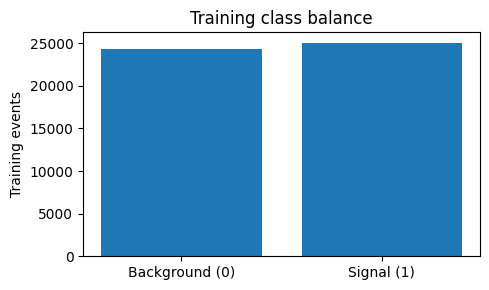

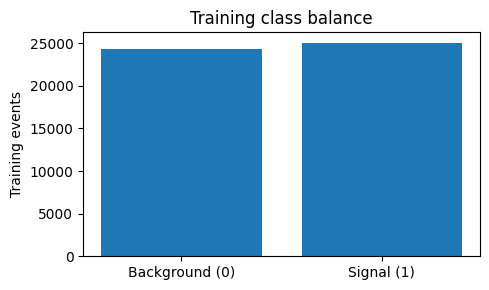

In [7]:
train_events = training_events(events_with_split) if events_with_split is not None else None
if train_events is not None:
    physics_features = feature_columns(train_events)
    print(f'Training rows: {len(train_events):,}; features: {len(physics_features)}')
    balance = class_balance(train_events)
    display(balance)
    display(plot_class_balance(balance))
else:
    print('EDA waits for the instructor dataset.')

## 9. Feature distributions and separation

Plot representative event-shape variables; rank all physics features by single-feature ROC-AUC. This ranking is not a final model result.

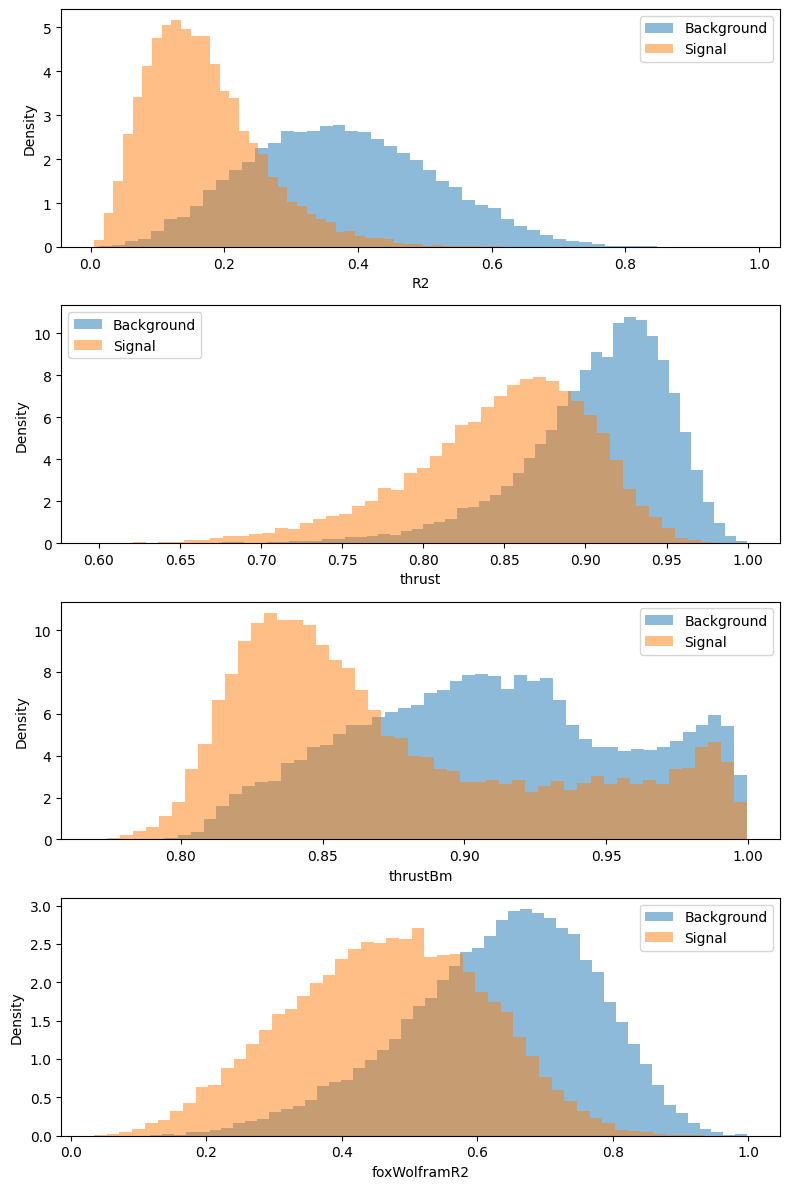

,feature,separation_auc,higher_for_signal,signal_median,background_median
0,R2,0.899589,0,0.155880,0.368883
1,thrustOm,0.840806,0,0.681984,0.789539
2,thrust,0.808055,0,0.856313,0.915072
3,KSFWVariables__bohoo2__bc,0.807830,0,0.002380,0.023772
4,KSFWVariables__bohoo2__cmFS1__bc,0.807830,0,0.002380,0.023772
5,foxWolframR2,0.795517,0,0.470395,0.646418
6,cosTBTO,0.785279,0,0.786943,0.961940
7,KSFWVariables__bohso02__bc,0.768273,0,0.060873,0.227615
8,KSFWVariables__bohso02__cmFS1__bc,0.758061,0,0.060328,0.212998
9,KSFWVariables__bohso12__bc,0.750460,0,0.030470,0.117299


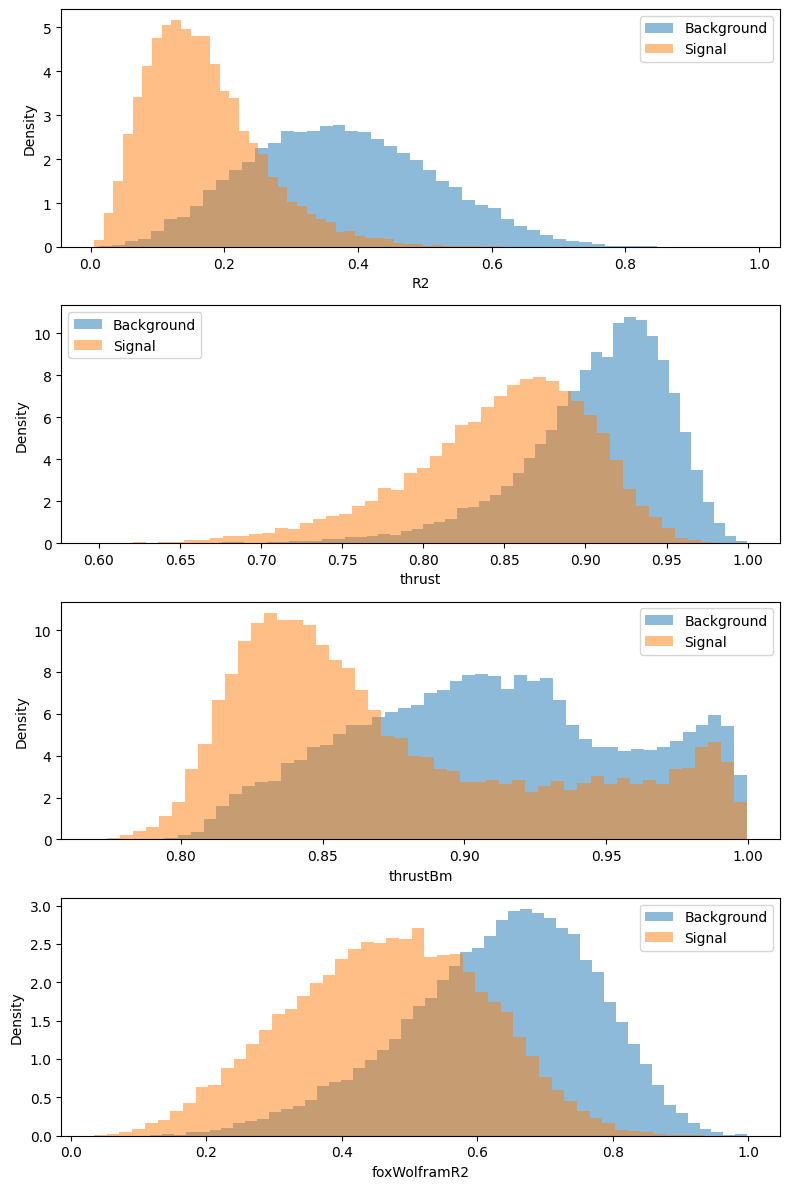

In [8]:
separation = None
if train_events is not None:
    display(plot_feature_distributions(train_events,
           ['R2', 'thrust', 'thrustBm', 'foxWolframR2']))
    separation = feature_separation(train_events)
    display(separation.head(15))
else:
    print('Feature EDA waits for training rows.')

## 10. Correlations and R2 physics check

Check whether signal has lower R2 than continuum; investigate any reversal before modeling.

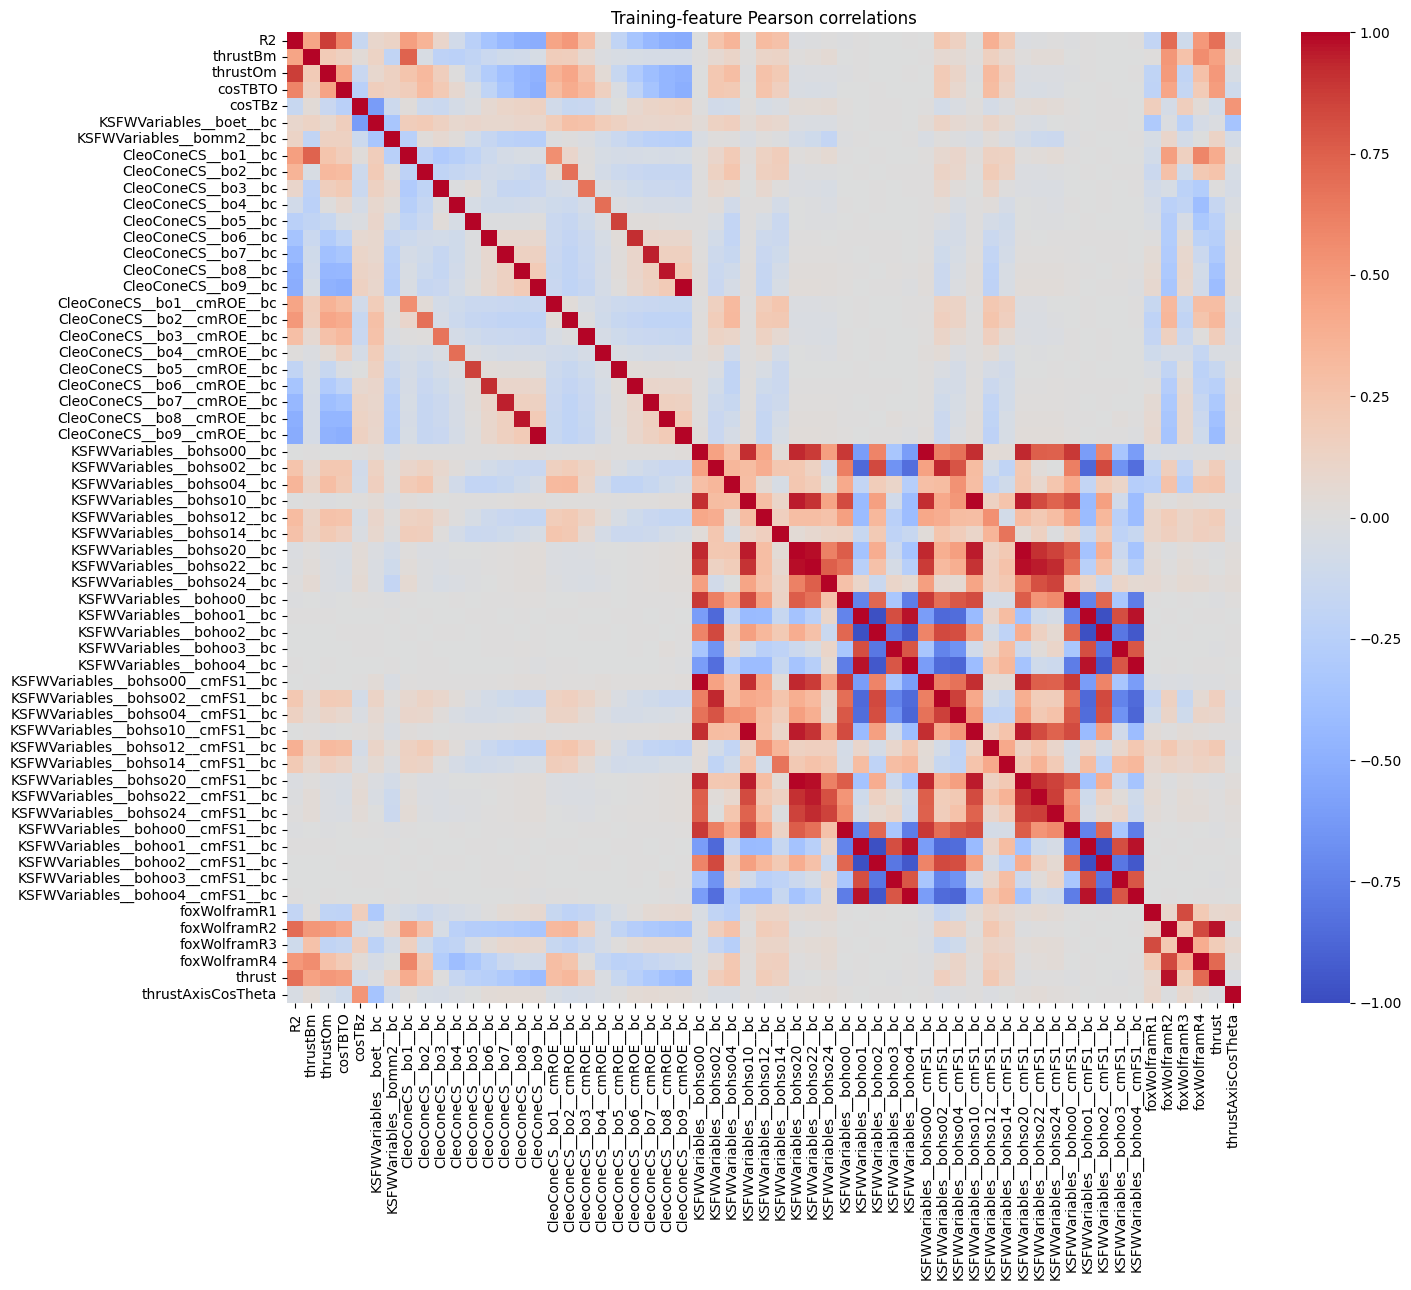

R2 median: signal=0.1559, background=0.3689
Expected R2 direction? True


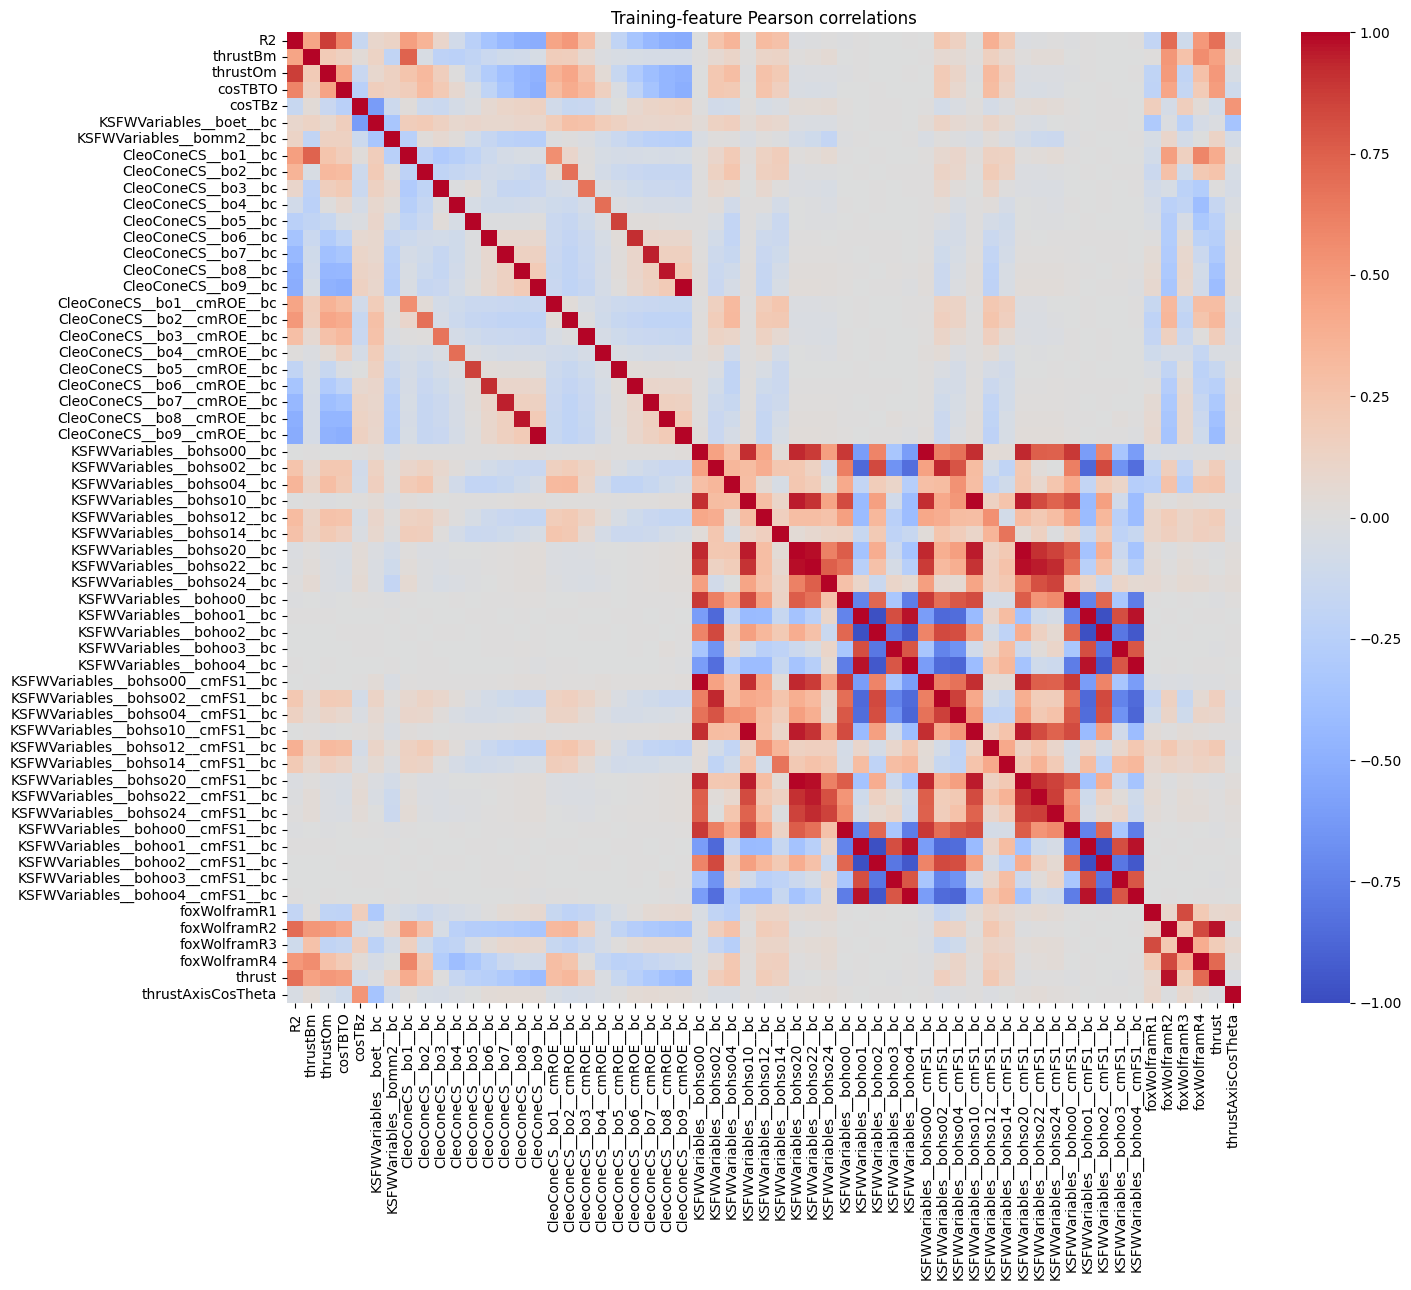

In [9]:
if train_events is not None:
    display(plot_correlation_heatmap(feature_correlations(train_events)))
    r2_summary = separation.loc[separation['feature'] == 'R2'].iloc[0]
    print(f"R2 median: signal={r2_summary['signal_median']:.4f}, background={r2_summary['background_median']:.4f}")
    print('Expected R2 direction?', r2_summary['signal_median'] < r2_summary['background_median'])
else:
    print('Physics check waits for training rows.')

## 11. SQLite read, write, and modify

Store and update only the derived training EDA summary; raw and cleaned events stay unchanged.

In [10]:
if separation is not None:
    eda_summary = separation.assign(status='computed')
    write_table(eda_summary, 'eda_feature_summary', if_exists='replace', db_path=DB_PATH)
    top_feature = eda_summary.iloc[0]['feature']
    changed = update_cell('eda_feature_summary', 'status', 'candidate_for_review',
                          'feature', top_feature, db_path=DB_PATH)
    print(f'Updated {changed} derived row(s): {top_feature}')
    display(read_table('eda_feature_summary', DB_PATH).head(10))
else:
    print('Derived SQLite summary waits for EDA.')

Updated 1 derived row(s): R2


,feature,separation_auc,higher_for_signal,signal_median,background_median,status
0,R2,0.899589,0,0.155880,0.368883,candidate_for_review
1,thrustOm,0.840806,0,0.681984,0.789539,computed
2,thrust,0.808055,0,0.856313,0.915072,computed
3,KSFWVariables__bohoo2__bc,0.807830,0,0.002380,0.023772,computed
4,KSFWVariables__bohoo2__cmFS1__bc,0.807830,0,0.002380,0.023772,computed
5,foxWolframR2,0.795517,0,0.470395,0.646418,computed
6,cosTBTO,0.785279,0,0.786943,0.961940,computed
7,KSFWVariables__bohso02__bc,0.768273,0,0.060873,0.227615,computed
8,KSFWVariables__bohso02__cmFS1__bc,0.758061,0,0.060328,0.212998,computed
9,KSFWVariables__bohso12__bc,0.750460,0,0.030470,0.117299,computed


## 12. Training-defined baselines

Compare a training-majority prediction and a training-selected R2 cut on validation. Test rows remain untouched.

In [11]:
baseline_definition, baseline_validation_results = (None, None)
if events_with_split is not None:
    baseline_definition, baseline_validation_results = evaluate_baselines(events_with_split)
    print(f'Training-selected R2 cut: {baseline_definition.r2_cut:.6f}')
    display(baseline_validation_results)
else:
    print('Baselines wait for the instructor data.')

Training-selected R2 cut: 0.251486


,model,feature_set,split,train_rows,validation_rows,features,accuracy,precision,recall,f1,roc_auc
0,Training Majority,baseline,validation,49424,10591,0,0.506562,0.506562,1.000000,0.672474,0.500000
1,R2 Cut,baseline,validation,49424,10591,1,0.819469,0.811137,0.838956,0.824812,0.898646


## 13. Ankit's full-feature models

Train Logistic Regression and Decision Tree on stored training rows; show provisional validation metrics only. The final test split stays untouched.

In [12]:
ankit_fitted_models, ankit_validation_results = (None, None)
if events_with_split is not None:
    ankit_fitted_models, ankit_validation_results = fit_ankit_validation(events_with_split)
    display(ankit_validation_results)
    print('Provisional validation metrics; final test rows are untouched.')
else:
    print('Modeling waits for the instructor data.')

,model,feature_set,split,train_rows,validation_rows,features,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,full,validation,49424,10591,59,0.842508,0.832285,0.863001,0.847365,0.918768
1,Decision Tree,full,validation,49424,10591,59,0.829572,0.802310,0.880522,0.839598,0.904724


Provisional validation metrics; final test rows are untouched.


## 14. Vishruti's full-feature models

Train a scaled Linear SVM and histogram Gradient Boosting BDT; compare all implemented methods on validation only.

In [13]:
vishruti_fitted_models, vishruti_validation_results = (None, None)
if events_with_split is not None:
    vishruti_fitted_models, vishruti_validation_results = fit_vishruti_validation(events_with_split)
    provisional_validation_table = pd.concat(
        [baseline_validation_results, ankit_validation_results, vishruti_validation_results],
        ignore_index=True,
    )
    display(provisional_validation_table.sort_values('roc_auc', ascending=False))
    print('Validation-only comparison; final test rows remain untouched.')
else:
    print('Vishruti models wait for the instructor data.')

,model,feature_set,split,train_rows,validation_rows,features,accuracy,precision,recall,f1,roc_auc
5,Histogram Gradient Boosting BDT,full,validation,49424,10591,59,0.876688,0.870009,0.889469,0.879631,0.949260
2,Logistic Regression,full,validation,49424,10591,59,0.842508,0.832285,0.863001,0.847365,0.918768
4,Linear SVM,full,validation,49424,10591,59,0.843546,0.830246,0.868779,0.849076,0.918645
3,Decision Tree,full,validation,49424,10591,59,0.829572,0.802310,0.880522,0.839598,0.904724
1,R2 Cut,baseline,validation,49424,10591,1,0.819469,0.811137,0.838956,0.824812,0.898646
0,Training Majority,baseline,validation,49424,10591,0,0.506562,0.506562,1.000000,0.672474,0.500000


Validation-only comparison; final test rows remain untouched.


## 15. Training-only feature reduction

Prune correlations above 0.95, inspect standardized PCA at 95% cumulative variance, rank tree importance, and freeze a 20-feature Logistic Regression RFE subset. Validation and test values do not influence this analysis.

Correlation pruning: 45 kept, 14 dropped
PCA components for at least 95% training variance: 23


,feature,importance
0,R2,0.935921
1,CleoConeCS__bo1__bc,0.018508
2,KSFWVariables__bomm2__bc,0.011456
3,CleoConeCS__bo1__cmROE__bc,0.009933
4,KSFWVariables__boet__bc,0.009142
5,thrustBm,0.005729
6,KSFWVariables__bohso20__bc,0.003564
7,CleoConeCS__bo2__bc,0.002424
8,cosTBz,0.001688
9,KSFWVariables__bohso02__bc,0.001635


,feature,selected,rank
0,CleoConeCS__bo1__bc,True,1
1,CleoConeCS__bo1__cmROE__bc,True,1
2,CleoConeCS__bo2__bc,True,1
3,CleoConeCS__bo2__cmROE__bc,True,1
4,CleoConeCS__bo3__bc,True,1
5,CleoConeCS__bo3__cmROE__bc,True,1
6,CleoConeCS__bo4__bc,True,1
7,CleoConeCS__bo4__cmROE__bc,True,1
8,KSFWVariables__bohoo0__cmFS1__bc,True,1
9,KSFWVariables__bohoo2__bc,True,1


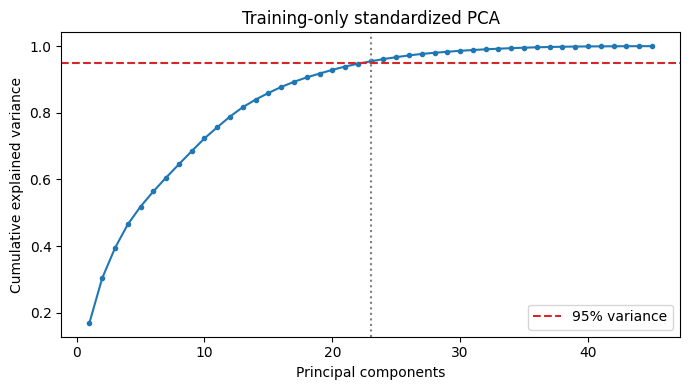

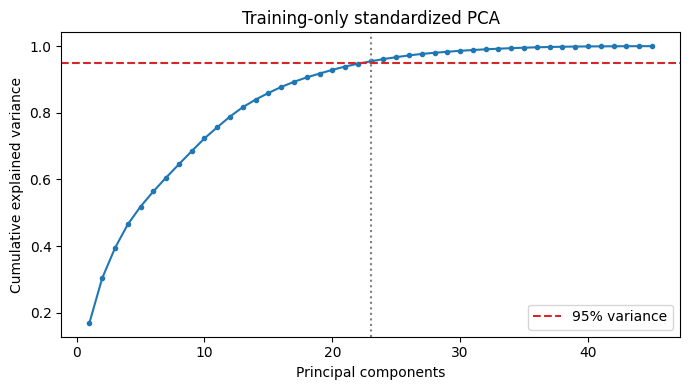

In [14]:
reduction = None
if events_with_split is not None:
    reduction = analyze_feature_reduction(events_with_split)
    print(f'Correlation pruning: {len(reduction.correlation_kept)} kept, {len(reduction.correlation_dropped)} dropped')
    print(f'PCA components for at least 95% training variance: {reduction.pca_components_95}')
    display(reduction.tree_importance.head(15))
    display(reduction.rfe_ranking.head(25))
    display(plot_pca_variance(reduction))
else:
    print('Feature reduction waits for the instructor data.')

## 16. Koustav's MLP

Compare the same scaled feed-forward neural network on all physics features and the frozen RFE subset. Its early-stopping partition is drawn only from training rows.

In [15]:
mlp_full_model, mlp_full_results = (None, None)
mlp_reduced_model, mlp_reduced_results = (None, None)
if reduction is not None:
    mlp_full_model, mlp_full_results = fit_koustav_mlp_validation(events_with_split)
    mlp_reduced_model, mlp_reduced_results = fit_koustav_mlp_validation(
        events_with_split, reduction.selected_features
    )
    display(pd.concat([mlp_full_results, mlp_reduced_results], ignore_index=True))
else:
    print('MLP validation waits for the training-only reduction result.')

,model,feature_set,split,train_rows,validation_rows,features,accuracy,precision,recall,f1,roc_auc
0,MLP,full,validation,49424,10591,59,0.869323,0.853993,0.895061,0.874044,0.941358
1,MLP,reduced_rfe20,validation,49424,10591,20,0.870173,0.863256,0.883691,0.873354,0.942158


## 17. Experimental physics-grouped CNN

Convolution is used only for ordered CLEO-cone and KSFW-moment families; remaining scalar measurements use a dense branch. PyTorch is optional so the core notebook remains runnable without the large dependency.

In [16]:
cnn_model, cnn_validation_results = (None, None)
if events_with_split is None:
    print('CNN validation waits for the instructor data.')
elif importlib.util.find_spec('torch') is None:
    print('CNN skipped: install the optional dependency with python -m pip install -r requirements-cnn.txt')
else:
    cnn_model, cnn_validation_results = fit_cnn_validation(events_with_split)
    display(cnn_validation_results)

,model,feature_set,split,train_rows,validation_rows,features,accuracy,precision,recall,f1,roc_auc
0,Physics-grouped 1D CNN,full_grouped,validation,49424,10591,59,0.854782,0.847593,0.869711,0.85851,0.930724


## 18. Provisional validation comparison

This table supports model and feature-set selection. It is not a final result because the held-out test split remains unopened.

In [17]:
if mlp_full_results is not None:
    validation_parts = [provisional_validation_table, mlp_full_results, mlp_reduced_results]
    if cnn_validation_results is not None:
        validation_parts.append(cnn_validation_results)
    koustav_validation_table = pd.concat(validation_parts, ignore_index=True)
    display(koustav_validation_table.sort_values('roc_auc', ascending=False))
    print('Freeze the final protocol before evaluating the test split.')
else:
    print('Combined comparison waits for Koustav model results.')

,model,feature_set,split,train_rows,validation_rows,features,accuracy,precision,recall,f1,roc_auc
5,Histogram Gradient Boosting BDT,full,validation,49424,10591,59,0.876688,0.870009,0.889469,0.879631,0.949260
7,MLP,reduced_rfe20,validation,49424,10591,20,0.870173,0.863256,0.883691,0.873354,0.942158
6,MLP,full,validation,49424,10591,59,0.869323,0.853993,0.895061,0.874044,0.941358
8,Physics-grouped 1D CNN,full_grouped,validation,49424,10591,59,0.854782,0.847593,0.869711,0.858510,0.930724
2,Logistic Regression,full,validation,49424,10591,59,0.842508,0.832285,0.863001,0.847365,0.918768
4,Linear SVM,full,validation,49424,10591,59,0.843546,0.830246,0.868779,0.849076,0.918645
3,Decision Tree,full,validation,49424,10591,59,0.829572,0.802310,0.880522,0.839598,0.904724
1,R2 Cut,baseline,validation,49424,10591,1,0.819469,0.811137,0.838956,0.824812,0.898646
0,Training Majority,baseline,validation,49424,10591,0,0.506562,0.506562,1.000000,0.672474,0.500000


Freeze the final protocol before evaluating the test split.


## 19. Evaluation design: two honest comparison studies

The project has two result sets because the models were evaluated at different stages, not because weaker results are being hidden.

**Study A ? frozen held-out test.** The six required classifier families, two simple baselines, and the predeclared reduced MLP were finalized using training/validation evidence. Their settings were then refit on all 60,015 development rows and evaluated once on 10,591 untouched test rows. This table supports the primary project conclusion.

**Study B ? development-only extension comparison.** Random Forest, the full-versus-reduced BDT sensitivity study, and the deeper dense network were proposed after Study A was complete. They therefore use the same five stratified outer folds over the 60,015 train+validation rows, producing one out-of-fold probability per row while excluding every original test row. These four rows can be compared directly with one another because their assessment rows and outer folds match.

The notebook places both studies together for readability, but does not create a single cross-study leaderboard: a test score and a development-OOF score answer related but statistically different questions.

## 20. Study A ? frozen held-out-test comparison

The notebook reads the committed artifacts rather than rerunning the one-shot evaluator. This protects the test set from repeated model selection and keeps the report reproducible.

,model,feature_set,split,fit_rows,test_rows,features,accuracy,precision,recall,f1,roc_auc
0,Histogram Gradient Boosting BDT,full,test,60015,10591,59,0.878387,0.870300,0.893010,0.881509,0.945678
1,MLP (full),full,test,60015,10591,59,0.873950,0.859436,0.898043,0.878316,0.941609
2,MLP (RFE-20),reduced_rfe20,test,60015,10591,20,0.872156,0.854517,0.901025,0.877155,0.939919
3,Physics-grouped 1D CNN,full_grouped,test,60015,10591,59,0.854027,0.843744,0.873625,0.858425,0.927270
4,Logistic Regression,full,test,60015,10591,59,0.842036,0.830824,0.864119,0.847145,0.915145
5,Linear SVM,full,test,60015,10591,59,0.842036,0.827305,0.869711,0.847978,0.915122
6,Decision Tree,full,test,60015,10591,59,0.829667,0.813855,0.860578,0.836565,0.902247
7,R2 Cut,baseline,test,60015,10591,1,0.818336,0.813103,0.832805,0.822836,0.896210
8,Training Majority,baseline,test,60015,10591,0,0.506562,0.506562,1.000000,0.672474,0.500000


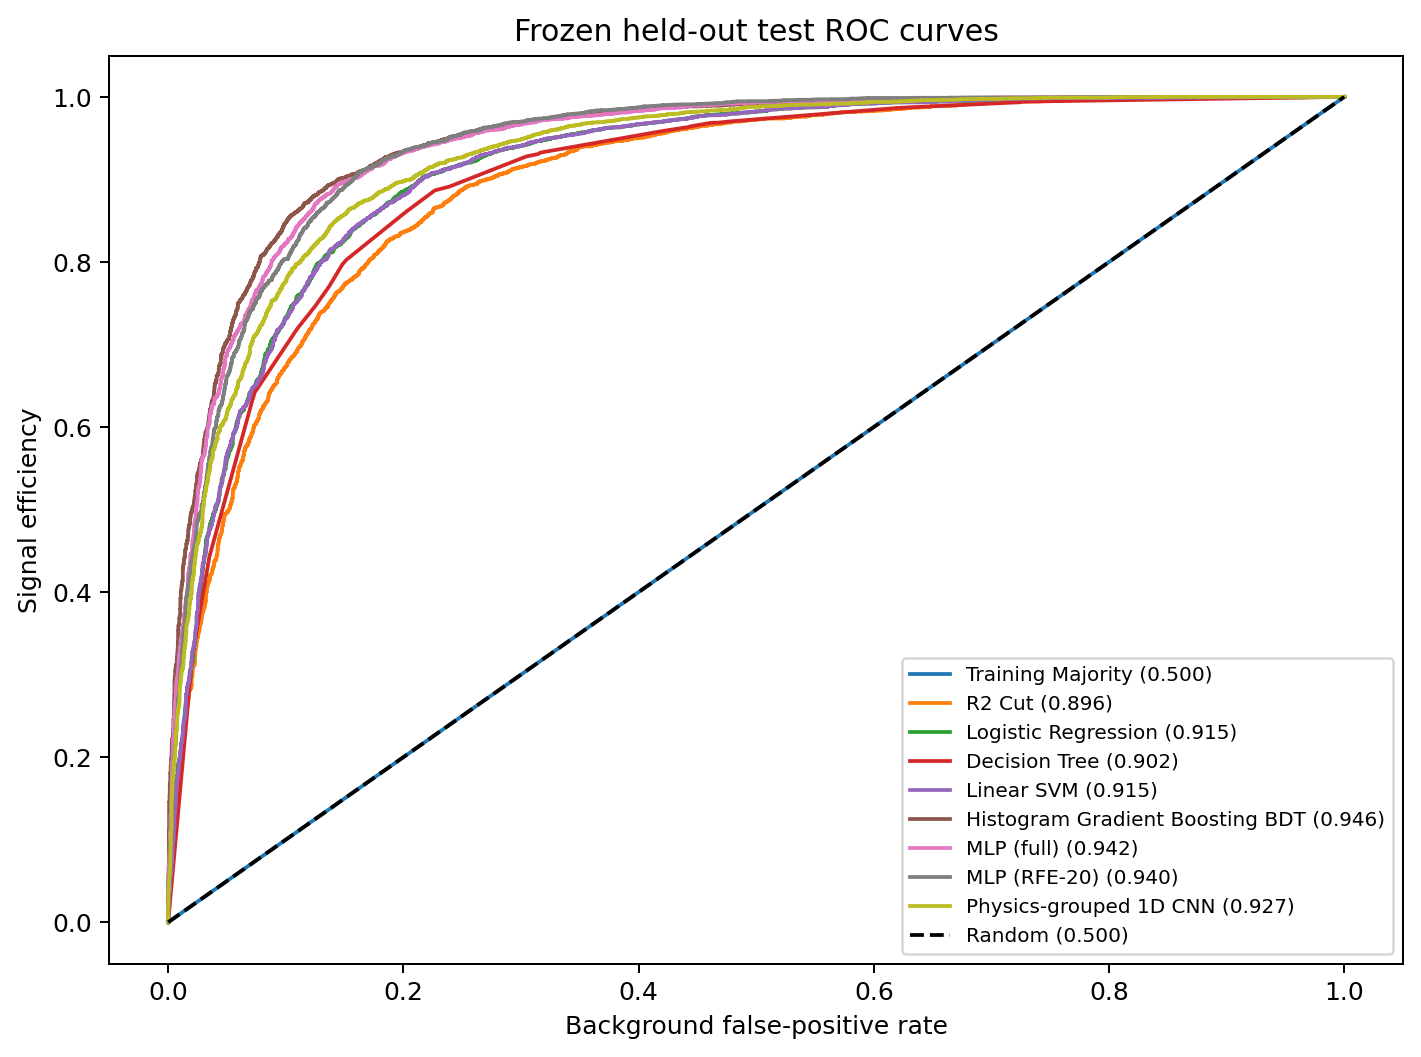

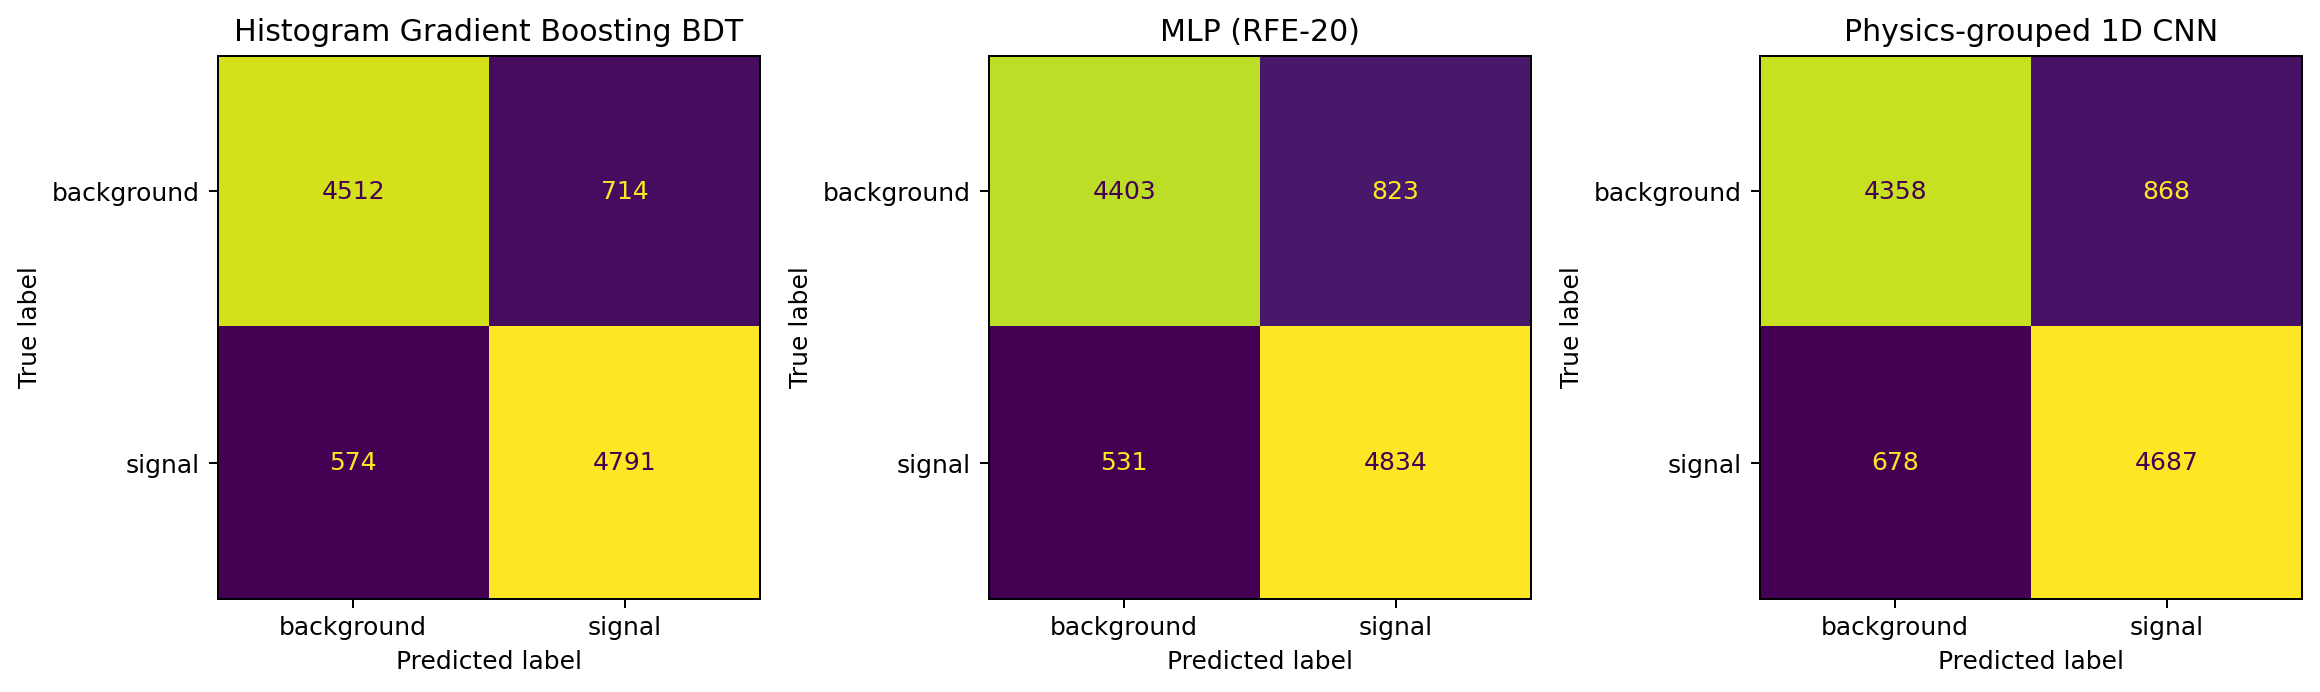

In [18]:
final_metrics_path = PROJECT_ROOT / 'results/tables/final_test_metrics.csv'
final_roc_path = PROJECT_ROOT / 'results/figures/final_test_roc.png'
final_confusion_path = PROJECT_ROOT / 'results/figures/final_test_confusion_matrices.png'
if final_metrics_path.is_file():
    final_metrics = pd.read_csv(final_metrics_path)
    display(final_metrics.sort_values('roc_auc', ascending=False))
    display(Image(filename=str(final_roc_path)))
    display(Image(filename=str(final_confusion_path)))
else:
    print('Frozen Study A artifacts are unavailable; do not recreate them casually.')

### Study A finding

The committed table ranks the histogram Gradient Boosting BDT first by point-estimate ROC-AUC, followed by the full and RFE-20 MLPs. These decimal differences are descriptive until Study E supplies paired uncertainty intervals. The RFE-20 result is also a historical fixed-selector result, not an end-to-end nested estimate.

This is the headline comparison because all listed configurations were fixed before the test was opened.

## 21. Study B ? additional development-OOF experiments

The extension models answer two follow-up questions: whether other nonlinear models work well with the frozen RFE-20 measurements, and how much the best tree family loses when reduced from 59 to 20 inputs. All rows below use five-fold development-only out-of-fold evaluation and exclude the original test set.

In [19]:
extension_paths = [
    PROJECT_ROOT / 'results/tables/posthoc_reduced_random_forest_cv.csv',
    PROJECT_ROOT / 'results/tables/posthoc_bdt_feature_comparison_cv.csv',
    PROJECT_ROOT / 'results/tables/posthoc_dense_rfe20_cv.csv',
]
missing_extension_paths = [path for path in extension_paths if not path.is_file()]
if not missing_extension_paths:
    extension_metrics = pd.concat(
        [pd.read_csv(path) for path in extension_paths], ignore_index=True
    ).sort_values('roc_auc', ascending=False)
    display(extension_metrics[[
        'model', 'feature_set', 'evaluation', 'rows', 'features',
        'accuracy', 'precision', 'recall', 'f1', 'roc_auc'
    ]])
else:
    print('Missing Study B artifacts:', [str(path) for path in missing_extension_paths])

,model,feature_set,evaluation,rows,features,accuracy,precision,recall,f1,roc_auc
1,"BDT (full, post-hoc)",full,development_5fold_oof,60015,59,0.877281,0.869162,0.892007,0.880436,0.948132
3,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,development_5fold_oof,60015,20,0.872465,0.854896,0.901184,0.877430,0.943197
2,"BDT (RFE-20, post-hoc)",reduced_rfe20,development_5fold_oof,60015,20,0.868999,0.860078,0.885428,0.872569,0.941913
0,"Random Forest (RFE-20, post-hoc)",reduced_rfe20,development_5fold_oof,60015,20,0.859485,0.851258,0.875592,0.863254,0.933212


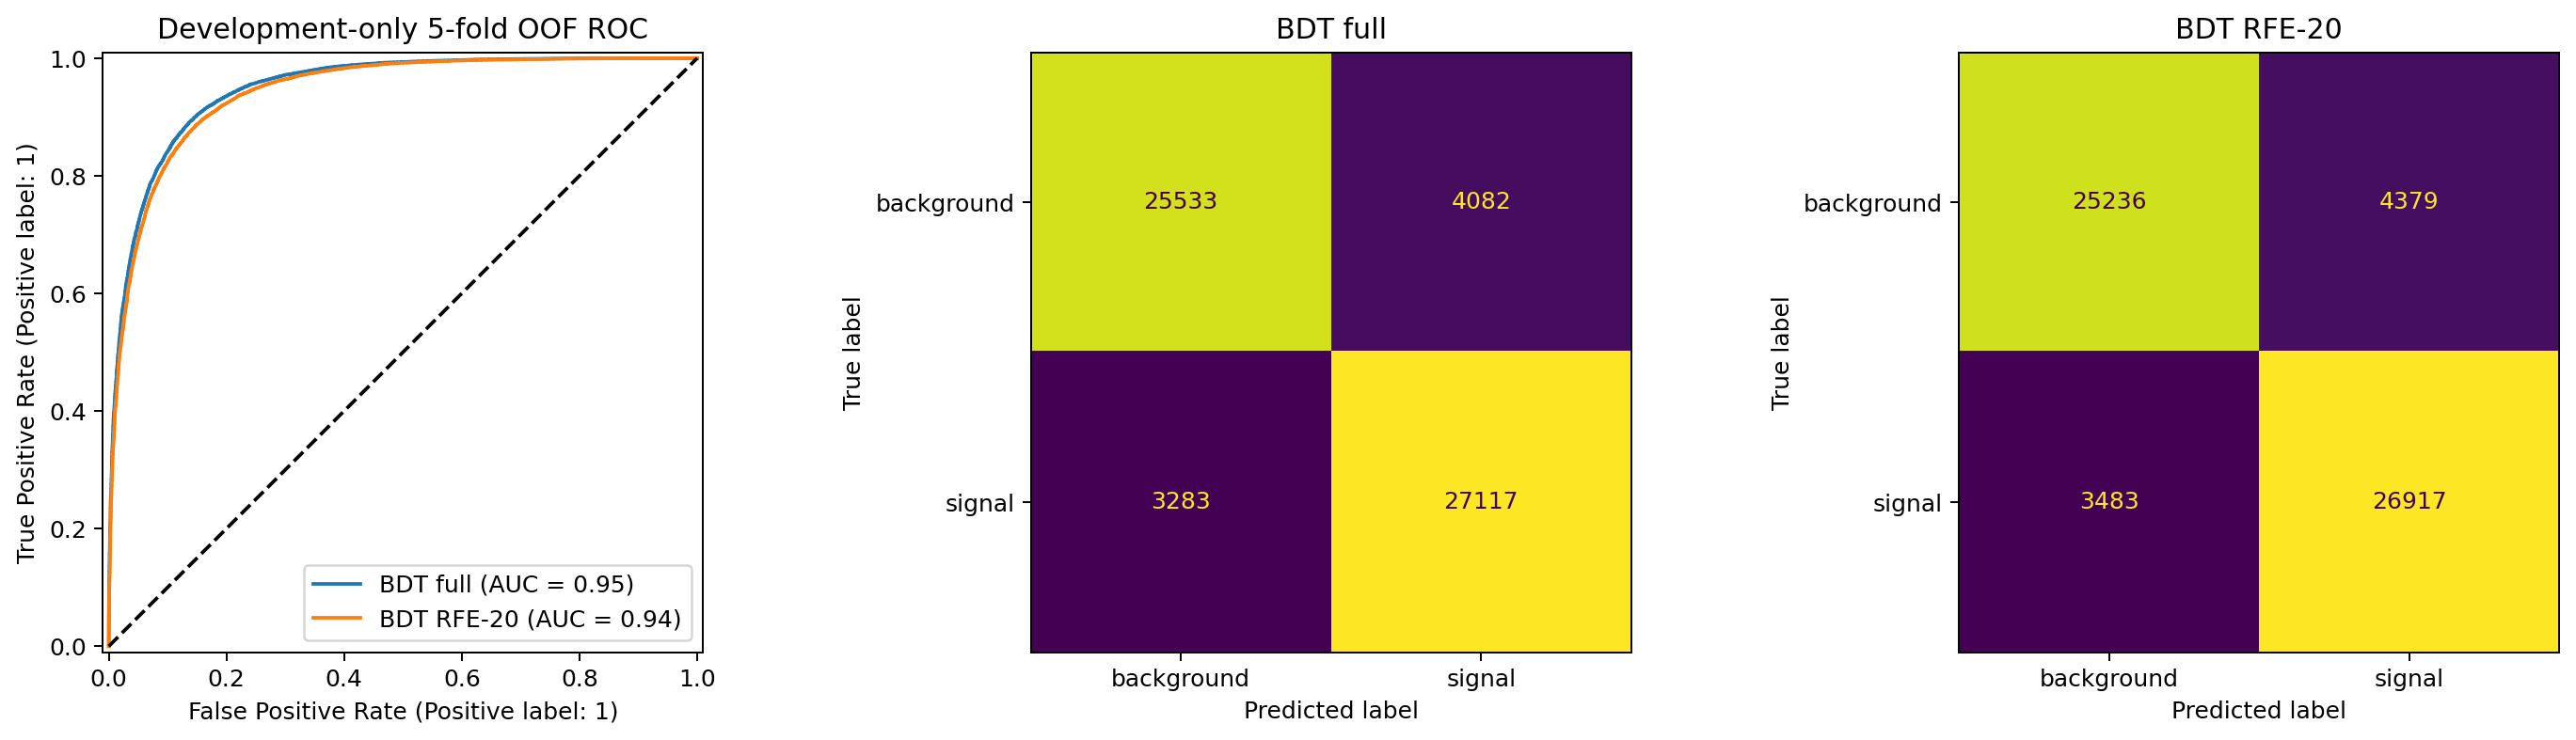

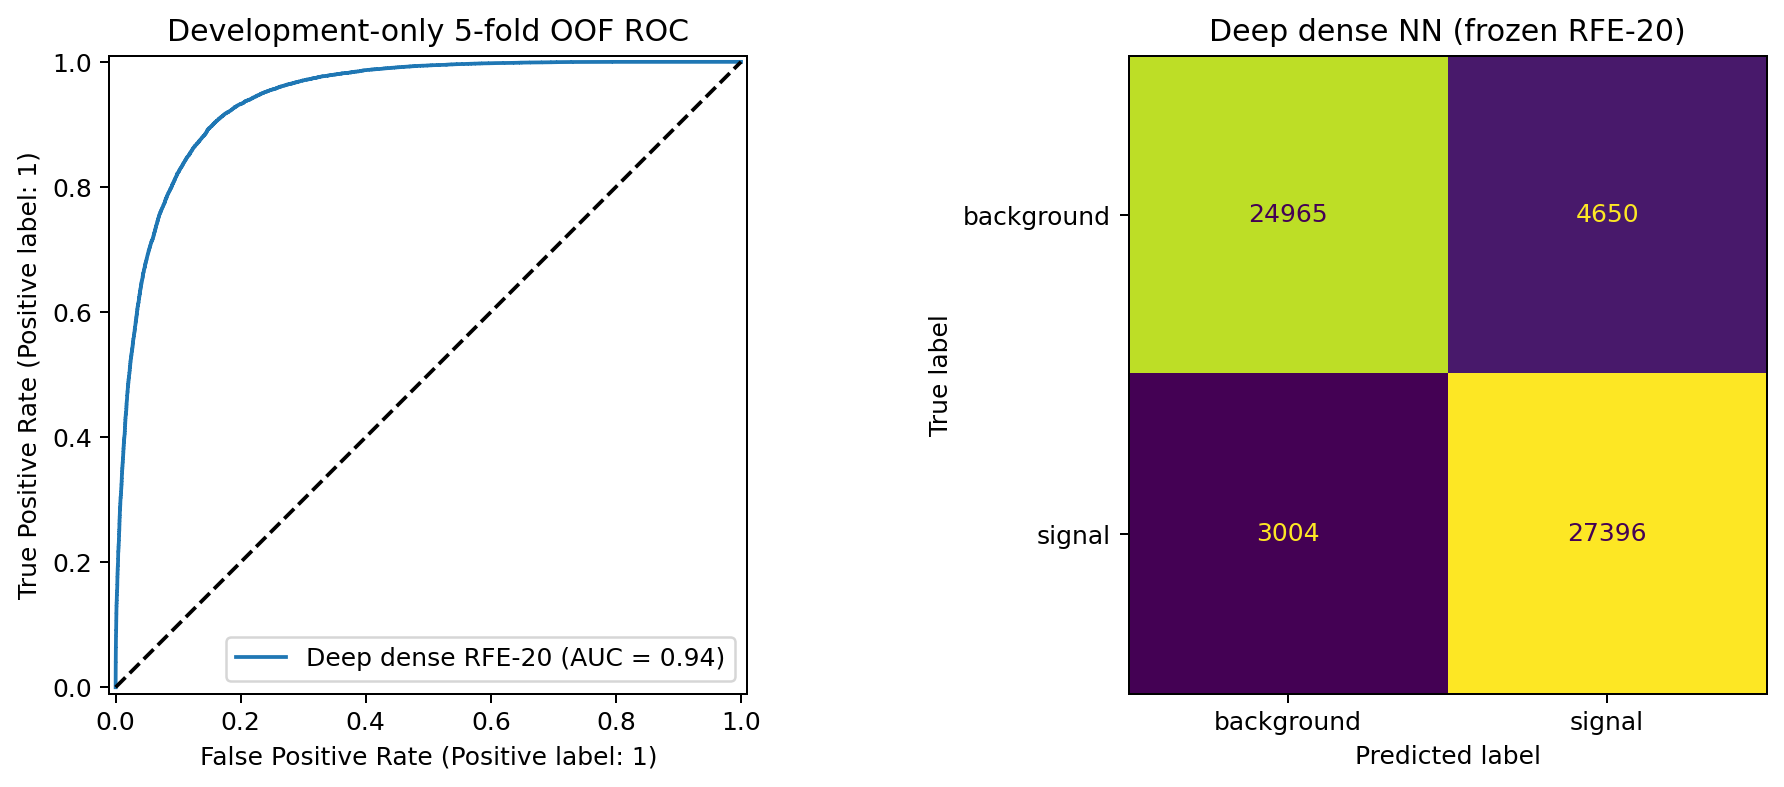

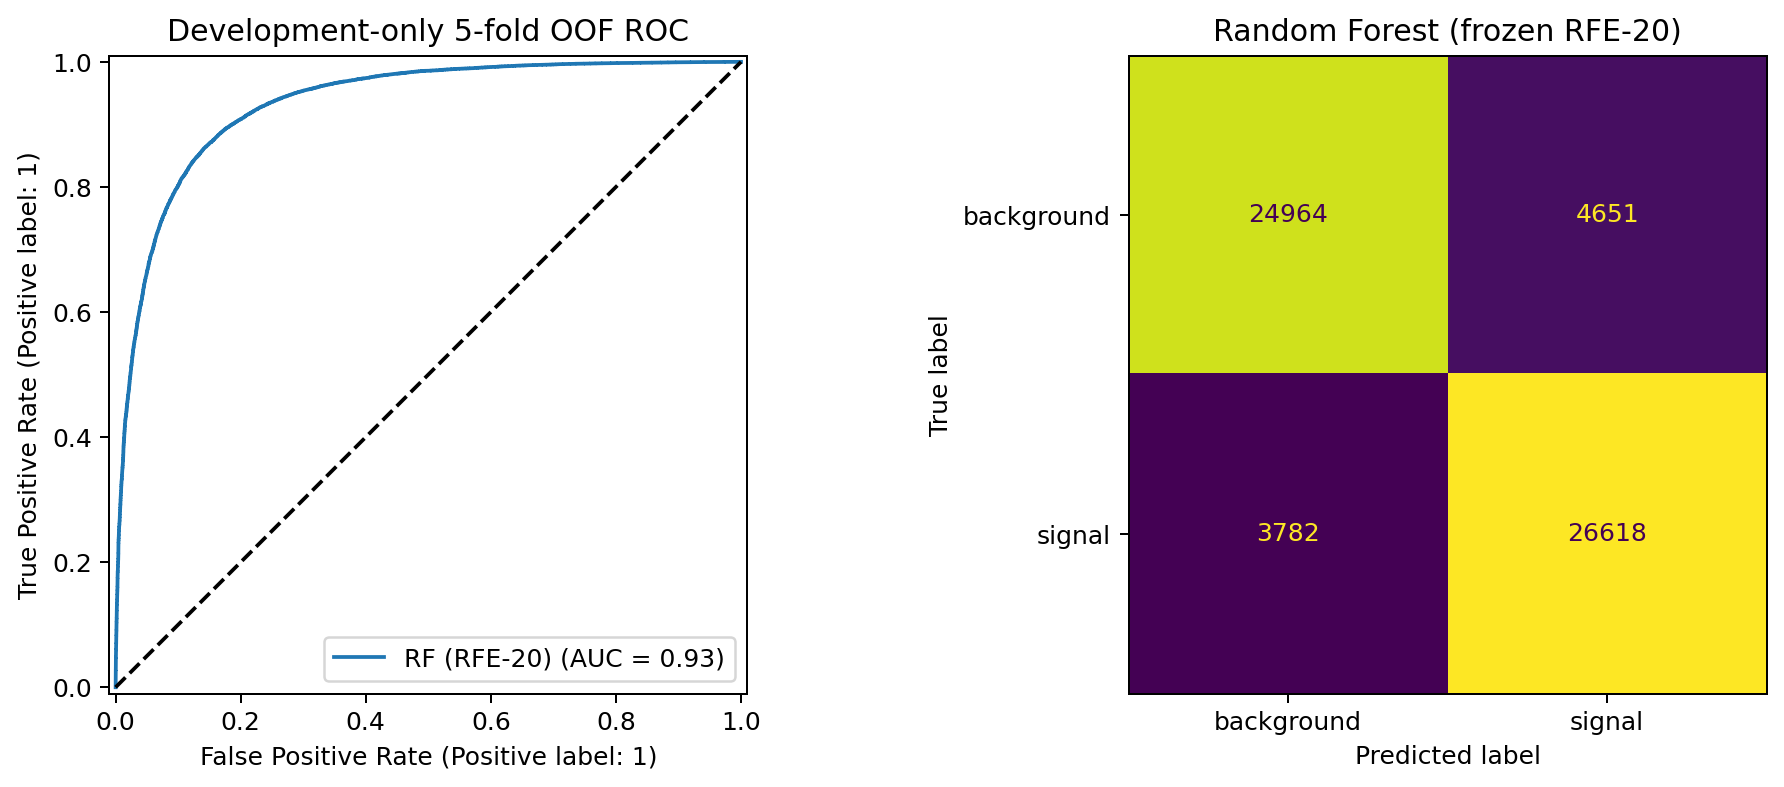

In [20]:
extension_figures = [
    PROJECT_ROOT / 'results/figures/posthoc_bdt_feature_comparison.png',
    PROJECT_ROOT / 'results/figures/posthoc_dense_rfe20_diagnostics.png',
    PROJECT_ROOT / 'results/figures/posthoc_reduced_random_forest_diagnostics.png',
]
for figure_path in extension_figures:
    if figure_path.is_file():
        display(Image(filename=str(figure_path)))

### Study B comparison

Within the common development-OOF protocol, the displayed table ranks the full BDT first by point-estimate ROC-AUC. The deep dense network, reduced BDT, and Random Forest are the reduced extensions.

The matched BDT comparison describes the cost of using the previously frozen RFE-20 list. Because that list was not reselected inside each fold, Study E—not this table—is the valid end-to-end estimate of feature selection.

The deep network selected epochs `(44, 58, 59, 60, 56)`. Two folds near the fixed 60-epoch ceiling indicate possible incomplete convergence; the budget was not increased after seeing the result.

## 22. Study C ? seed robustness of the representative best models

The full BDT and deep dense RFE-20 network represent the strongest full and reduced conclusions. Ten fixed seeds (42, 123, 2026, 7, 19, 73, 314, 2718, 4096, and 10007) each create a complete five-fold development-only OOF prediction set. The table reports seed-level metrics and mean, sample standard deviation, minimum, and maximum across the ten complete repetitions. Original test rows remain excluded. Run `python -m scripts.run_seed_robustness` separately.

,model,feature_set,seed,folds,rows,features,accuracy,precision,recall,f1,roc_auc,evaluation,mean_fitted_epochs
0,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,7,5,60015,20,0.871449,0.856783,0.895987,0.875947,0.943567,development_5fold_oof,48.6
1,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,19,5,60015,20,0.872632,0.858973,0.895592,0.876900,0.943349,development_5fold_oof,47.6
2,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,42,5,60015,20,0.872465,0.854896,0.901184,0.877430,0.943197,development_5fold_oof,55.4
3,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,73,5,60015,20,0.870516,0.856936,0.893553,0.874861,0.942605,development_5fold_oof,42.0
4,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,123,5,60015,20,0.872482,0.858480,0.895954,0.876817,0.943410,development_5fold_oof,51.6
5,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,314,5,60015,20,0.873215,0.859332,0.896447,0.877497,0.944001,development_5fold_oof,55.4
6,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,2026,5,60015,20,0.872365,0.858743,0.895296,0.876639,0.943454,development_5fold_oof,48.2
7,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,2718,5,60015,20,0.871832,0.860559,0.891414,0.875715,0.943788,development_5fold_oof,51.4
8,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,4096,5,60015,20,0.872449,0.857053,0.897961,0.877030,0.943752,development_5fold_oof,56.0
9,"Deep Dense NN (RFE-20, post-hoc)",reduced_rfe20,10007,5,60015,20,0.870732,0.856051,0.895362,0.875265,0.942649,development_5fold_oof,47.6


,model,metric,mean,std,minimum,maximum,seeds
0,"Deep Dense NN (RFE-20, post-hoc)",accuracy,0.872014,0.000869,0.870516,0.873215,10
1,"Deep Dense NN (RFE-20, post-hoc)",precision,0.857781,0.001716,0.854896,0.860559,10
2,"Deep Dense NN (RFE-20, post-hoc)",recall,0.895875,0.002557,0.891414,0.901184,10
3,"Deep Dense NN (RFE-20, post-hoc)",f1,0.876410,0.000911,0.874861,0.877497,10
4,"Deep Dense NN (RFE-20, post-hoc)",roc_auc,0.943377,0.000460,0.942605,0.944001,10
5,Histogram Gradient Boosting BDT (full),accuracy,0.876478,0.000534,0.875648,0.877281,10
6,Histogram Gradient Boosting BDT (full),precision,0.868138,0.000623,0.866980,0.869162,10
7,Histogram Gradient Boosting BDT (full),recall,0.891566,0.000699,0.890329,0.892730,10
8,Histogram Gradient Boosting BDT (full),f1,0.879696,0.000522,0.878948,0.880436,10
9,Histogram Gradient Boosting BDT (full),roc_auc,0.948093,0.000194,0.947593,0.948268,10


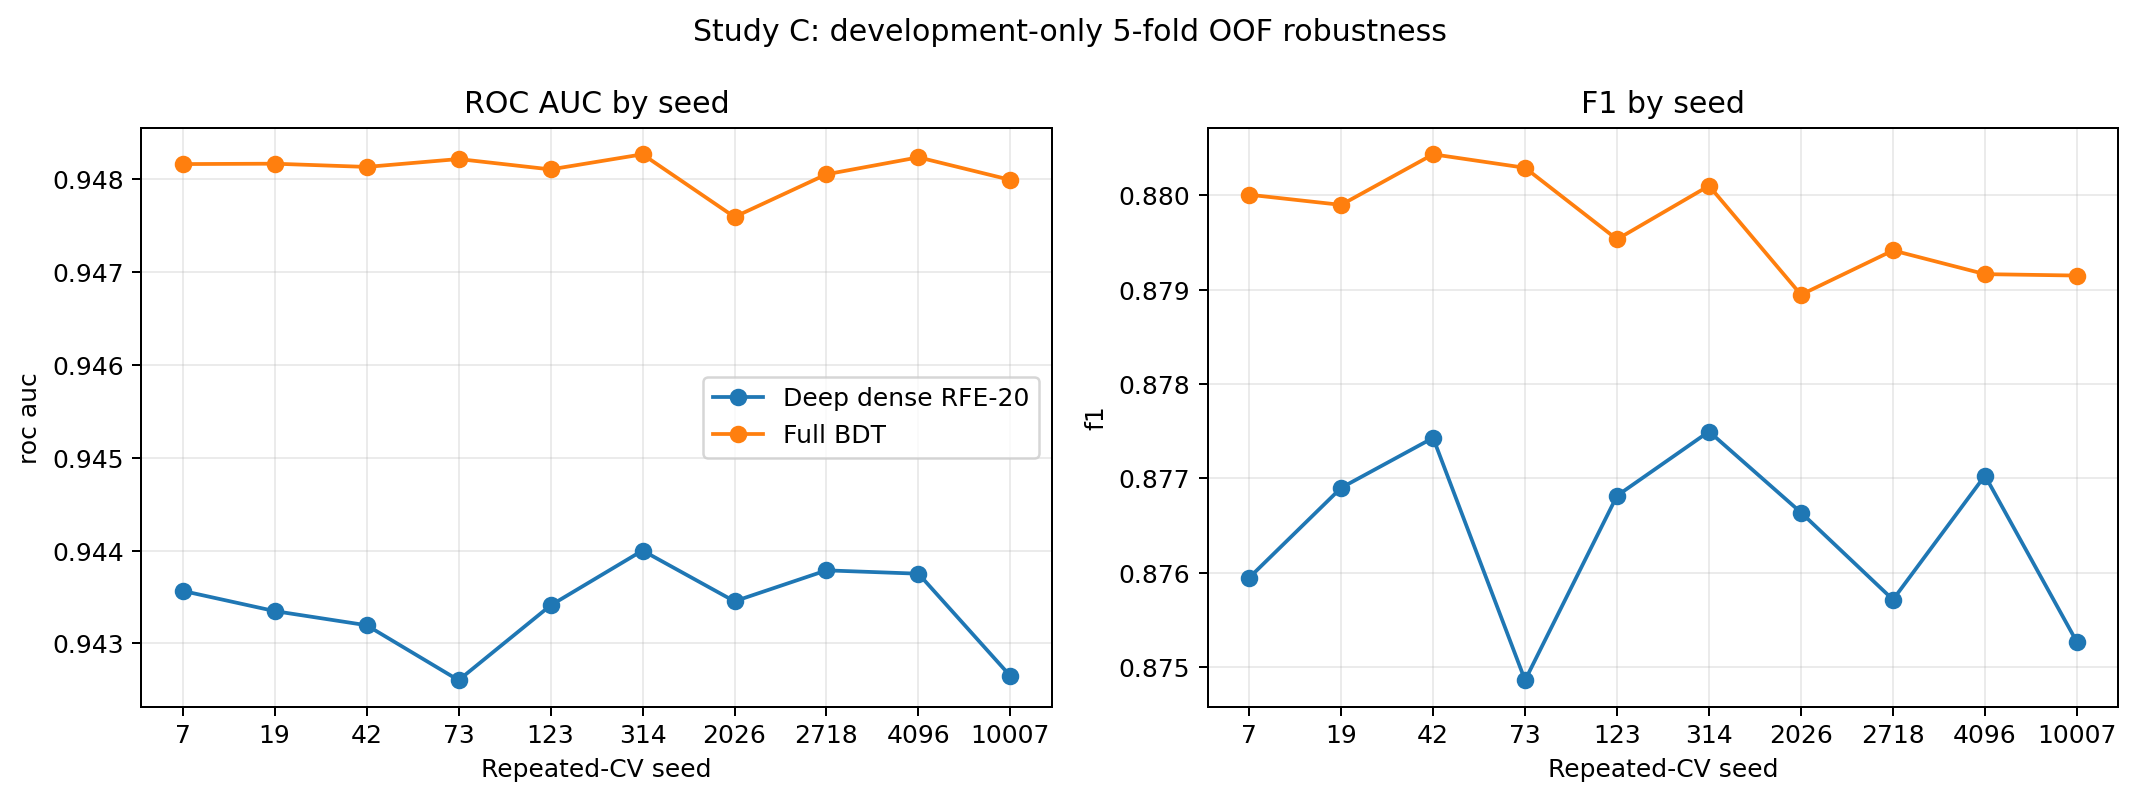

In [21]:
seed_rows_path = PROJECT_ROOT / 'results/tables/seed_robustness_per_seed.csv'
seed_summary_path = PROJECT_ROOT / 'results/tables/seed_robustness_summary.csv'
seed_figure_path = PROJECT_ROOT / 'results/figures/seed_robustness.png'
if seed_rows_path.is_file() and seed_summary_path.is_file():
    display(pd.read_csv(seed_rows_path))
    display(pd.read_csv(seed_summary_path))
    display(Image(filename=str(seed_figure_path)))
else:
    print('Study C has not run. Use python -m scripts.run_seed_robustness; test rows remain excluded.')

### Study C result

The seed-level and summary tables above are the numerical source of truth; the notebook does not duplicate their values in markdown.

The ordering is unchanged across these ten reruns, but their correlated spread measures only sensitivity to fold and training randomness on the same data. It is not a confidence interval and does not establish population-level superiority.

## 23. Study D ? full versus reduced Linear Discriminant Analysis

LDA asks whether the two classes can be separated by one covariance-aware linear discriminant. A StandardScaler and automatic covariance shrinkage are fitted inside every fold. Full 59-feature and frozen RFE-20 variants use the same ten seeds and five development-only folds; original test rows remain excluded. Run `python -m scripts.run_lda_study` separately.

,model,feature_set,seed,folds,evaluation,rows,features,accuracy,precision,recall,f1,roc_auc
0,Shrinkage LDA (full),full,42,5,development_5fold_oof,60015,59,0.821111,0.819615,0.829375,0.824466,0.899918
1,Shrinkage LDA (RFE-20),reduced_rfe20,42,5,development_5fold_oof,60015,20,0.818429,0.789870,0.874079,0.829843,0.894897
2,Shrinkage LDA (full),full,123,5,development_5fold_oof,60015,59,0.821095,0.819963,0.828783,0.824349,0.899852
3,Shrinkage LDA (RFE-20),reduced_rfe20,123,5,development_5fold_oof,60015,20,0.818512,0.789970,0.874112,0.829913,0.894852
4,Shrinkage LDA (full),full,2026,5,development_5fold_oof,60015,59,0.821061,0.819701,0.829112,0.824380,0.899912
5,Shrinkage LDA (RFE-20),reduced_rfe20,2026,5,development_5fold_oof,60015,20,0.818079,0.789480,0.873882,0.829539,0.894806
6,Shrinkage LDA (full),full,7,5,development_5fold_oof,60015,59,0.821561,0.820064,0.829803,0.824905,0.899967
7,Shrinkage LDA (RFE-20),reduced_rfe20,7,5,development_5fold_oof,60015,20,0.818445,0.789927,0.874013,0.829846,0.895062
8,Shrinkage LDA (full),full,19,5,development_5fold_oof,60015,59,0.821295,0.820033,0.829178,0.824580,0.899887
9,Shrinkage LDA (RFE-20),reduced_rfe20,19,5,development_5fold_oof,60015,20,0.818262,0.789635,0.874079,0.829714,0.894850


,model,metric,mean,std,minimum,maximum,seeds
0,Shrinkage LDA (full),accuracy,0.821171,0.000354,0.820645,0.821911,10
1,Shrinkage LDA (full),precision,0.819799,0.000257,0.819378,0.820110,10
2,Shrinkage LDA (full),recall,0.829237,0.001022,0.827961,0.831776,10
3,Shrinkage LDA (full),f1,0.824490,0.000455,0.823928,0.825531,10
4,Shrinkage LDA (full),roc_auc,0.899909,0.000061,0.899800,0.899993,10
5,Shrinkage LDA (RFE-20),accuracy,0.818444,0.000173,0.818079,0.818662,10
6,Shrinkage LDA (RFE-20),precision,0.789903,0.000207,0.789480,0.790147,10
7,Shrinkage LDA (RFE-20),recall,0.874056,0.000118,0.873882,0.874276,10
8,Shrinkage LDA (RFE-20),f1,0.829851,0.000148,0.829539,0.830041,10
9,Shrinkage LDA (RFE-20),roc_auc,0.894893,0.000090,0.894763,0.895062,10


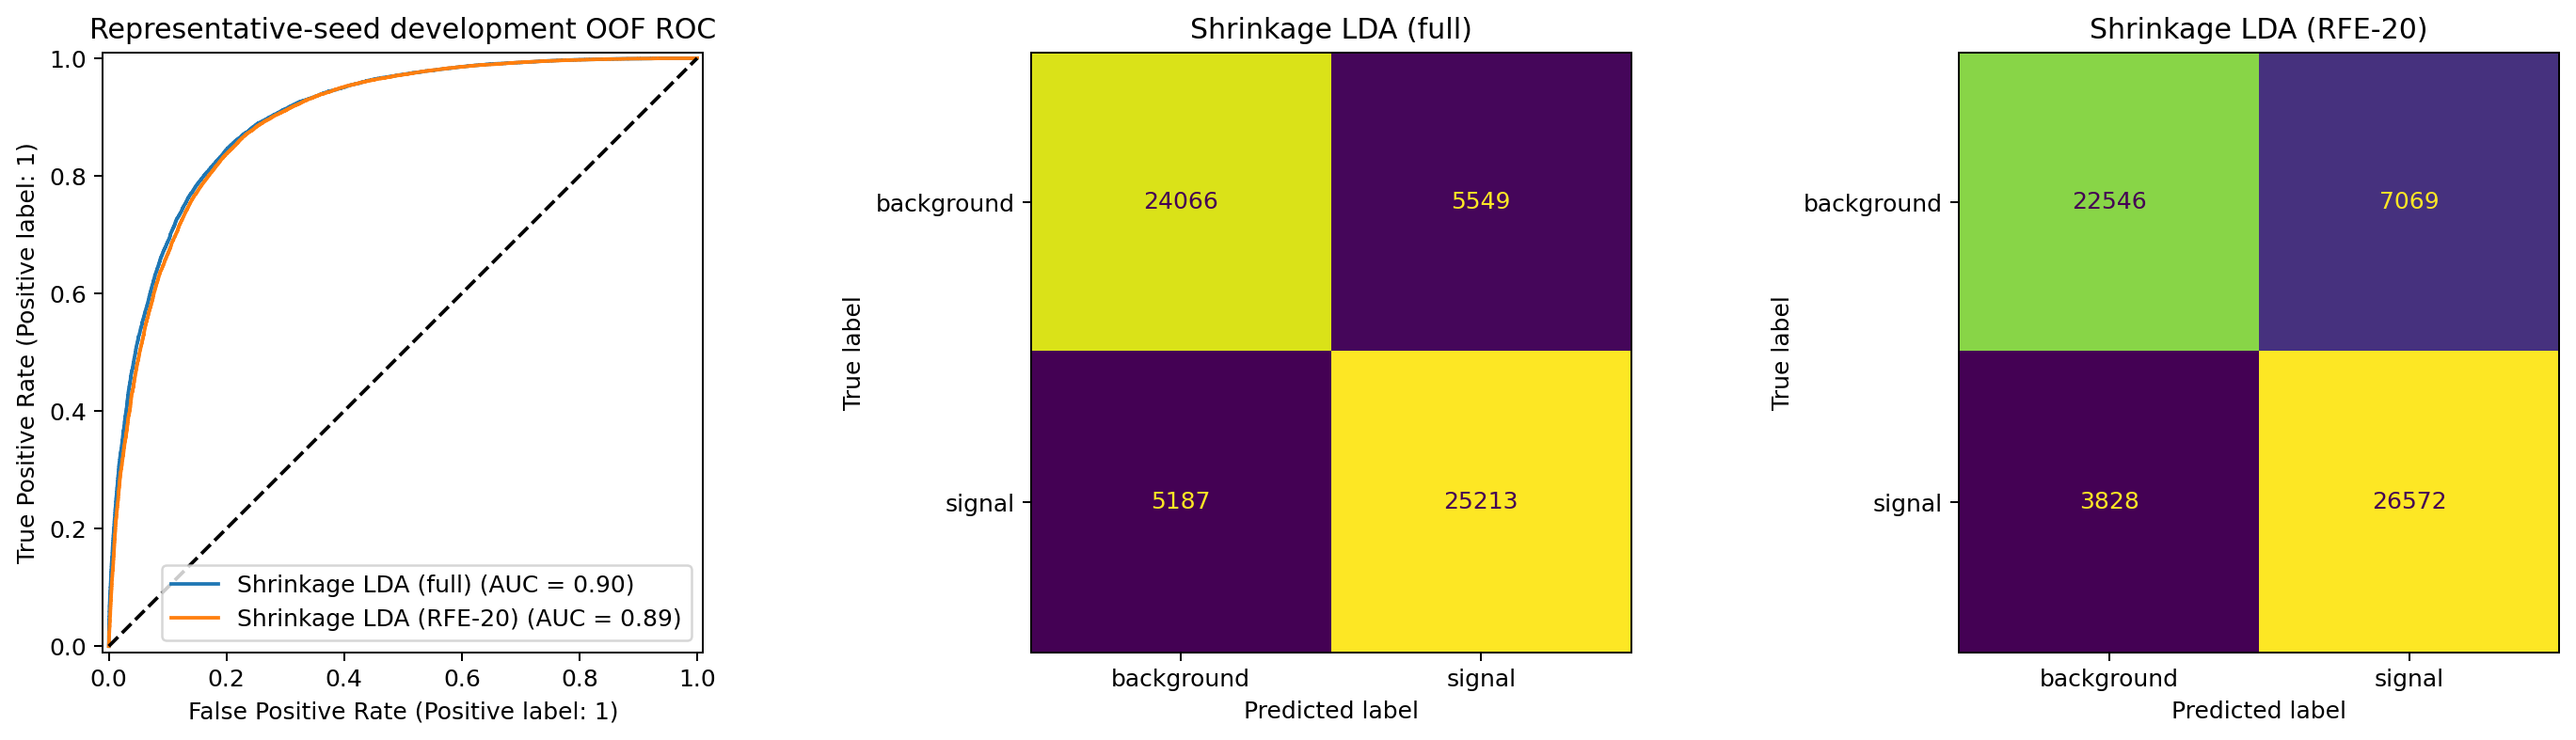

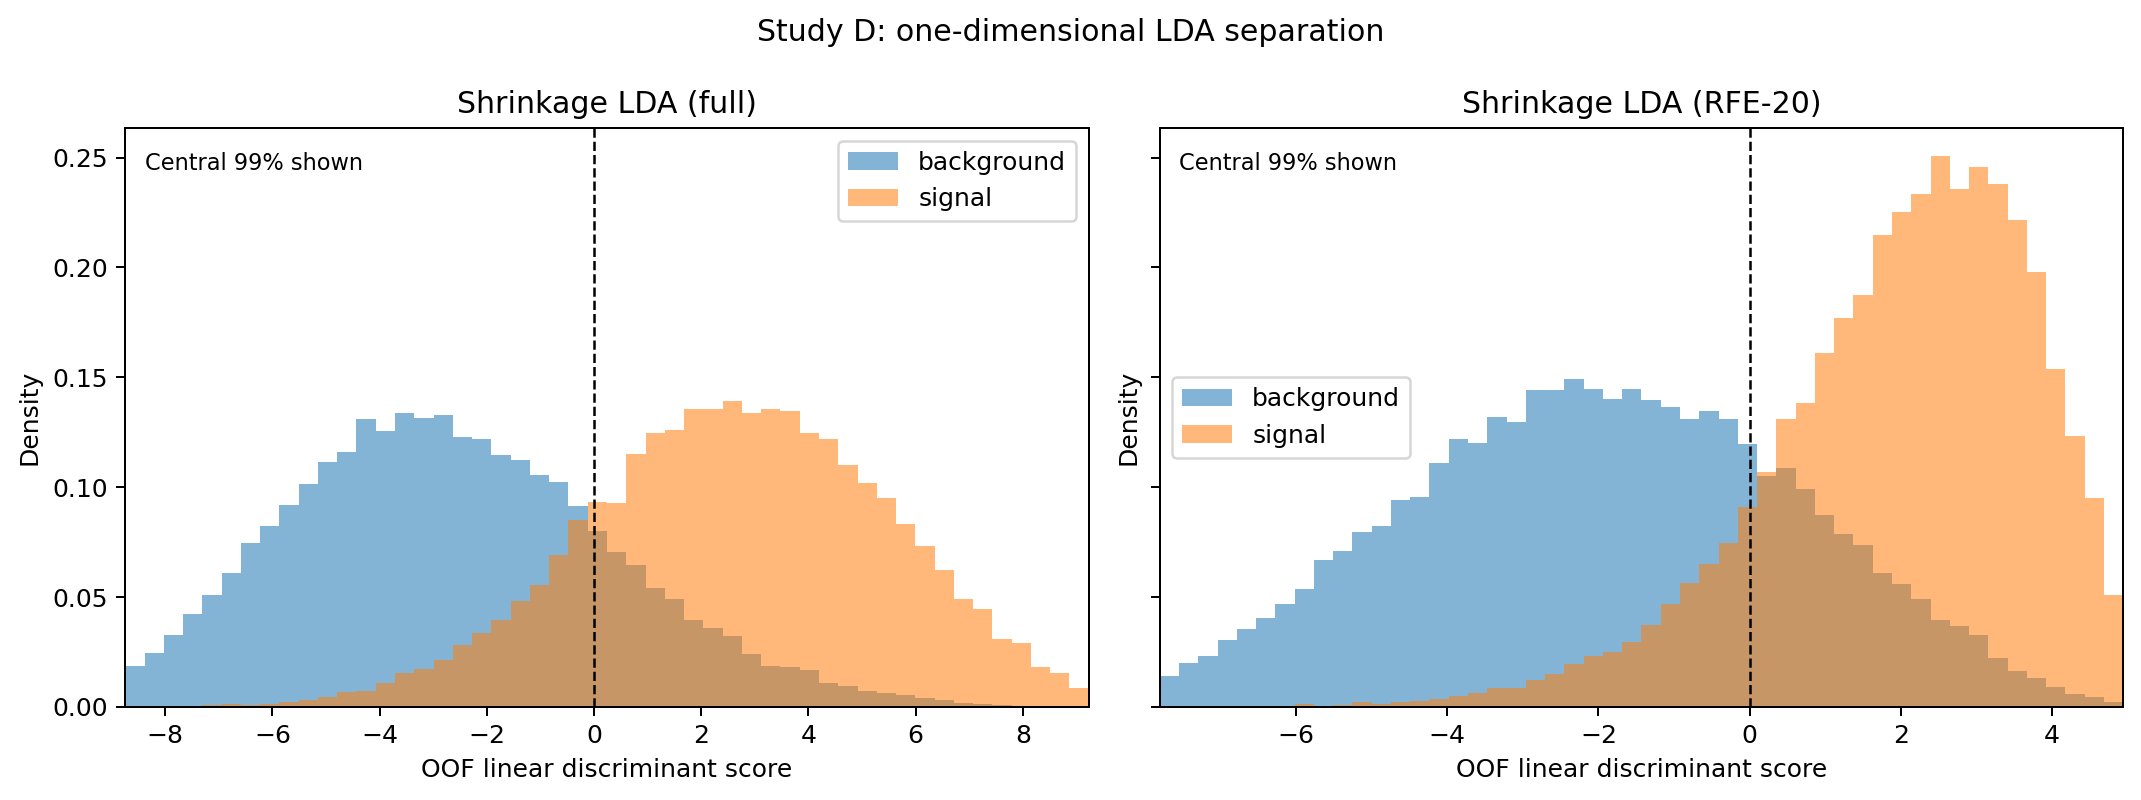

In [22]:
lda_rows_path = PROJECT_ROOT / 'results/tables/lda_per_seed.csv'
lda_summary_path = PROJECT_ROOT / 'results/tables/lda_summary.csv'
lda_diagnostics_path = PROJECT_ROOT / 'results/figures/lda_diagnostics.png'
lda_scores_path = PROJECT_ROOT / 'results/figures/lda_discriminant_scores.png'
if lda_rows_path.is_file() and lda_summary_path.is_file():
    display(pd.read_csv(lda_rows_path))
    display(pd.read_csv(lda_summary_path))
    display(Image(filename=str(lda_diagnostics_path)))
    display(Image(filename=str(lda_scores_path)))
else:
    print('Study D has not run. Use python -m scripts.run_lda_study; original test rows remain excluded.')

### Study D result

The seed-level and summary tables above are the numerical source of truth; the notebook does not duplicate their values in markdown.

The displayed table shows that full LDA is the better ranker and is slightly more accurate, while reduced LDA trades precision for recall and can therefore have higher threshold-specific F1 despite lower ROC-AUC. The discriminant plots show the central 99% of scores to keep rare extreme values from hiding the class overlap; metrics still use every row.

Under this development-only repeated-OOF setting, the displayed point estimates favor the nonlinear models. This is evidence consistent with useful nonlinear relationships, not proof that model class alone causes the difference because tuning budgets were not originally equal.

## 24. Study E — methodology correction

Studies A–D remain historical results. Study E corrects their inferential limits without using the test set for new model selection. The audit reconstructs fixed Study-A predictions for paired bootstrap ROC-AUC intervals, physics operating points, a log-scale ROC, and six-process acceptance. A separate nested development-only study fits permutation selection, PCA, and equal four-candidate classical tuning entirely inside each outer fold. Run `python -m scripts.run_methodology_correction --stage audit` first, then the longer `--stage nested` command.

,model,roc_auc,ci_95_low,ci_95_high,bootstrap_iterations
5,Histogram Gradient Boosting BDT,0.945678,0.941651,0.949814,2000
6,MLP (full),0.941609,0.937335,0.945845,2000
7,MLP (RFE-20),0.939919,0.935539,0.944238,2000
2,Logistic Regression,0.915161,0.909535,0.920477,2000
4,Linear SVM,0.915122,0.909515,0.920410,2000
3,Decision Tree,0.902247,0.896522,0.907933,2000
1,R2 Cut,0.896210,0.890198,0.902247,2000
0,Training Majority,0.500000,0.500000,0.500000,2000


,reference,comparison,auc_difference,ci_95_low,ci_95_high,bootstrap_iterations
0,Histogram Gradient Boosting BDT,Training Majority,0.445678,0.441651,0.449814,2000
1,Histogram Gradient Boosting BDT,R2 Cut,0.049468,0.045880,0.053668,2000
3,Histogram Gradient Boosting BDT,Decision Tree,0.043431,0.040132,0.046990,2000
4,Histogram Gradient Boosting BDT,Linear SVM,0.030556,0.027493,0.033821,2000
2,Histogram Gradient Boosting BDT,Logistic Regression,0.030517,0.027388,0.033812,2000
6,Histogram Gradient Boosting BDT,MLP (RFE-20),0.005759,0.003356,0.008314,2000
5,Histogram Gradient Boosting BDT,MLP (full),0.004069,0.001792,0.006417,2000
7,MLP (full),MLP (RFE-20),0.001690,-0.001055,0.004308,2000


,target_signal_efficiency,signal_efficiency,background_efficiency,background_rejection,threshold,model
10,0.90,0.900093,0.144661,6.912698,0.478946,Histogram Gradient Boosting BDT
12,0.90,0.900093,0.154420,6.475836,0.490304,MLP (full)
14,0.90,0.900652,0.157290,6.357664,0.500681,MLP (RFE-20)
4,0.90,0.900093,0.214504,4.661909,0.428501,Logistic Regression
8,0.90,0.900093,0.215653,4.637090,-0.086784,Linear SVM
2,0.90,0.900093,0.271144,3.688073,-0.282843,R2 Cut
6,0.90,0.927866,0.304631,3.282663,0.345522,Decision Tree
0,0.90,1.000000,1.000000,1.000000,0.506540,Training Majority
11,0.95,0.950606,0.238041,4.200965,0.273863,Histogram Gradient Boosting BDT
15,0.95,0.950047,0.238615,4.190858,0.310695,MLP (RFE-20)


,model,target_signal_efficiency,type,process,rows,signal_acceptance
0,Histogram Gradient Boosting BDT,0.90,0,charged_BB,80,0.850000
1,Histogram Gradient Boosting BDT,0.90,1,neutral_BB,5285,0.900851
2,Histogram Gradient Boosting BDT,0.90,2,ccbar,3492,0.142325
3,Histogram Gradient Boosting BDT,0.90,3,uubar,1243,0.150442
4,Histogram Gradient Boosting BDT,0.90,4,ddbar,260,0.142308
5,Histogram Gradient Boosting BDT,0.90,5,ssbar,231,0.151515
6,Histogram Gradient Boosting BDT,0.95,0,charged_BB,80,0.937500
7,Histogram Gradient Boosting BDT,0.95,1,neutral_BB,5285,0.950804
8,Histogram Gradient Boosting BDT,0.95,2,ccbar,3492,0.238832
9,Histogram Gradient Boosting BDT,0.95,3,uubar,1243,0.234916


,model,feature_set,evaluation,rows,outer_folds,inner_folds,candidates,accuracy,precision,recall,f1,roc_auc
0,Histogram Gradient Boosting BDT,full,nested_5x3_development_oof,60015,5,3,4,0.870516,0.894935,0.843388,0.868397,0.948134
1,Histogram Gradient Boosting BDT,nested_permutation_20,nested_5x3_development_oof,60015,5,3,4,0.876131,0.867503,0.891645,0.879408,0.947495
2,Histogram Gradient Boosting BDT,nested_pca95,nested_5x3_development_oof,60015,5,3,4,0.843606,0.835173,0.861217,0.847995,0.919874
3,Logistic Regression,full,nested_5x3_development_oof,60015,5,3,4,0.834658,0.866223,0.796612,0.829960,0.918547
4,Linear SVM,full,nested_5x3_development_oof,60015,5,3,4,0.773140,0.916315,0.607632,0.730711,0.918259
5,Decision Tree,full,nested_5x3_development_oof,60015,5,3,4,0.840990,0.836631,0.852566,0.844523,0.913471


,fold,model,feature_set,candidate_count,best_inner_roc_auc,best_parameters,pca_components
0,1,Logistic Regression,full,4,0.917590,"{""model__C"": 1.0}",NaN
1,1,Decision Tree,full,4,0.910524,"{""max_depth"": 8, ""min_samples_leaf"": 50}",NaN
2,1,Linear SVM,full,4,0.917783,"{""model__C"": 1.0}",NaN
3,1,Histogram Gradient Boosting BDT,full,4,0.946564,"{""max_leaf_nodes"": 31, ""min_samples_leaf"": 70}",NaN
4,1,Histogram Gradient Boosting BDT,nested_permutation_20,4,0.945632,"{""max_leaf_nodes"": 31, ""min_samples_leaf"": 70}",NaN
5,1,Histogram Gradient Boosting BDT,nested_pca95,4,0.918487,"{""model__max_leaf_nodes"": 31, ""model__min_samp...",23.0
6,2,Logistic Regression,full,4,0.918828,"{""model__C"": 1.0}",NaN
7,2,Decision Tree,full,4,0.911899,"{""max_depth"": 8, ""min_samples_leaf"": 50}",NaN
8,2,Linear SVM,full,4,0.918675,"{""model__C"": 1.0}",NaN
9,2,Histogram Gradient Boosting BDT,full,4,0.946988,"{""max_leaf_nodes"": 31, ""min_samples_leaf"": 30}",NaN


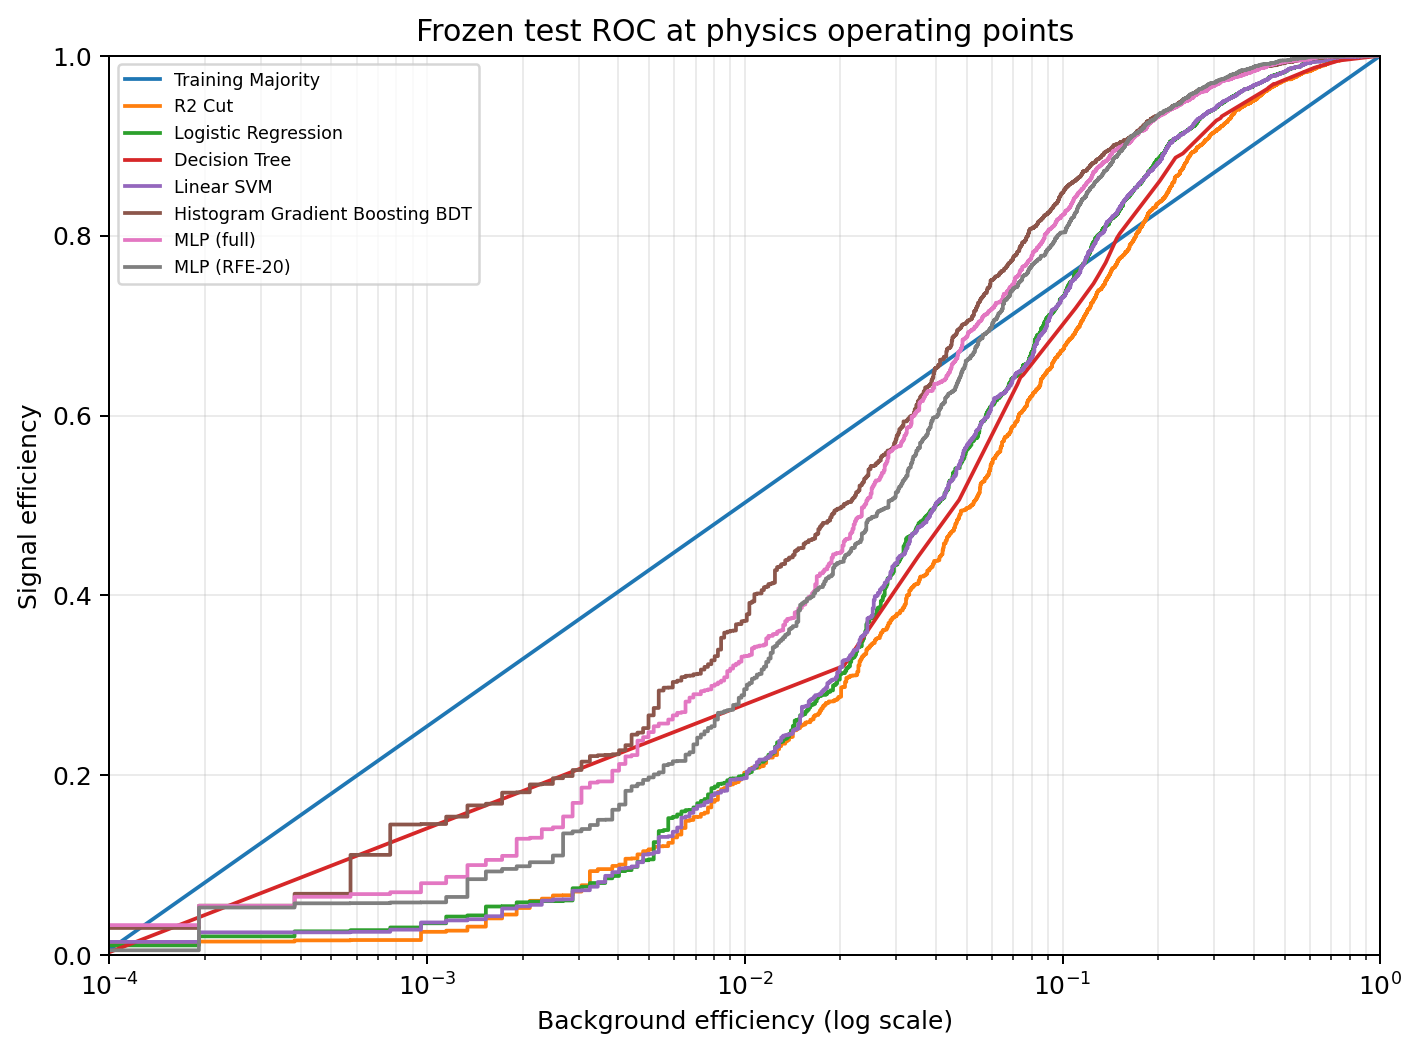

Frozen-test BDT AUC 0.9457 (paired-bootstrap 95% CI 0.9417–0.9498).
Full-minus-RFE MLP AUC 0.0017 (95% CI -0.0011–0.0043).
BDT background rejection at 90% signal efficiency: 6.91.
BDT background rejection at 95% signal efficiency: 4.20.
Best nested development result: Histogram Gradient Boosting BDT / full, AUC 0.9481.


In [23]:
methodology_paths = {
    'auc': PROJECT_ROOT / 'results/tables/methodology_test_auc_bootstrap.csv',
    'differences': PROJECT_ROOT / 'results/tables/methodology_test_auc_differences.csv',
    'operating': PROJECT_ROOT / 'results/tables/methodology_test_operating_points.csv',
    'process': PROJECT_ROOT / 'results/tables/methodology_test_process_efficiencies.csv',
    'nested': PROJECT_ROOT / 'results/tables/methodology_nested_metrics.csv',
    'tuning': PROJECT_ROOT / 'results/tables/methodology_nested_tuning.csv',
    'roc': PROJECT_ROOT / 'results/figures/methodology_test_log_roc.png',
}
if all(path.is_file() for path in methodology_paths.values()):
    method_auc = pd.read_csv(methodology_paths['auc'])
    method_diff = pd.read_csv(methodology_paths['differences'])
    method_operating = pd.read_csv(methodology_paths['operating'])
    method_process = pd.read_csv(methodology_paths['process'])
    method_nested = pd.read_csv(methodology_paths['nested'])
    method_tuning = pd.read_csv(methodology_paths['tuning'])
    display(method_auc.sort_values('roc_auc', ascending=False))
    display(method_diff.sort_values('auc_difference', ascending=False))
    display(method_operating.sort_values(['target_signal_efficiency', 'background_rejection'], ascending=[True, False]))
    display(method_process)
    display(method_nested.sort_values('roc_auc', ascending=False))
    display(method_tuning)
    display(Image(filename=str(methodology_paths['roc'])))
    best = method_nested.sort_values('roc_auc', ascending=False).iloc[0]
    bdt_ci = method_auc.loc[method_auc['model'] == 'Histogram Gradient Boosting BDT'].iloc[0]
    mlp_delta = method_diff.loc[(method_diff['reference'] == 'MLP (full)') & (method_diff['comparison'] == 'MLP (RFE-20)')].iloc[0]
    bdt_points = method_operating.loc[method_operating['model'] == 'Histogram Gradient Boosting BDT'].sort_values('target_signal_efficiency')
    print(f"Frozen-test BDT AUC {bdt_ci.roc_auc:.4f} (paired-bootstrap 95% CI {bdt_ci.ci_95_low:.4f}–{bdt_ci.ci_95_high:.4f}).")
    print(f"Full-minus-RFE MLP AUC {mlp_delta.auc_difference:.4f} (95% CI {mlp_delta.ci_95_low:.4f}–{mlp_delta.ci_95_high:.4f}).")
    for row in bdt_points.itertuples(): print(f"BDT background rejection at {row.target_signal_efficiency:.0%} signal efficiency: {row.background_rejection:.2f}.")
    print(f"Best nested development result: {best['model']} / {best.feature_set}, AUC {best.roc_auc:.4f}.")
else:
    print('Study E artifacts are pending; run the audit and nested commands outside the notebook.')

### How to interpret Study E

The bootstrap interval estimates uncertainty from resampling the fixed test sample; the paired AUC-difference interval is the relevant evidence for whether two fixed models separate this sample differently. It is not detector-domain uncertainty. Seed spreads in Study C are only partition/training sensitivity. Background rejection at fixed signal efficiency is class-ratio independent, whereas accuracy, precision, and F1 inherit this nearly balanced sample's class mixture. No luminosity-weighted significance is reported because the instructor file supplies neither event weights nor validated cross sections.

## 25. How the studies fit together

Studies A–D record the original project sequence. Study E supplies the defensible uncertainty, physics operating points, process breakdown, and end-to-end nested reduction comparison needed to qualify those earlier observations.

These studies are complementary, not one mixed leaderboard. Study A is one fixed held-out sample; Studies B–D are later development analyses; Study E is the corrected inferential audit.

## 26. Limitations

- The instructor dataset is simulated analysis-level data, not real detector data.
- The CSV has no confirmed collision/event-group identifier, so splitting is row-stratified and cannot rule out event-level dependence between rows.
- Study A uses one fixed 70/15/15 split; its Study-E bootstrap interval describes resampling of that test sample, not future detector data.
- The original RFE-20 studies are non-nested historical analyses; only Study E estimates an end-to-end fold-local reduction pipeline.
- The sample is nearly balanced and has no event weights, so accuracy, precision, F1, and any unweighted significance do not transfer to physical Belle II yields.
- The CNN representation is physics-motivated but is not detector geometry.
- The deeper dense network uses one fixed architecture and may be constrained by its 60-epoch ceiling.

These limitations bound the claims to reproducible classification on the supplied sample; they do not establish deployment performance on future Belle II data.

## 27. Conclusion

Event-shape measurements provide useful separation between spherical B-pair signal and jet-like continuum background. The committed result tables—not hand-copied prose—provide the numerical model comparisons.

Study C measures sensitivity to fold and training seeds, not population uncertainty. Study E adds paired test-sample uncertainty, HEP operating points, per-process diagnostics, and nested feature reduction so the final interpretation no longer rests on decimal-level point-estimate differences or leaked feature selection.

The project demonstrates private-data ingestion, SQLite read/write/modify operations, leakage-aware EDA, feature interpretation and reduction, classical and neural classifiers, full/reduced comparisons, required metrics, diagnostic plots, repeated-seed robustness, interpretable discriminant analysis, reproducible artifacts, and explicit claim boundaries.